# Facial Feature Classification Challenge — Cats & Dogs (8 classes)

End-to-end deep learning pipeline for the Kaggle competition. The notebook follows the assessment tasks:

| Section | Assessment task |
|---|---|
| 0 | Setup, configuration & reproducibility |
| 1 | Dataset exploration and understanding |
| 2 | Data preprocessing and pipeline preparation |
| 3 | Model selection and pipeline development |
| 4 | Training strategy and overfitting / underfitting management |
| 5 | Model evaluation and Kaggle submission |
| 6 | Results analysis and improvement strategies |

Reusable pipeline code (Dataset, transforms, models, train / evaluate loops, Grad-CAM) lives in **`ffc_lib.py`** next to this notebook. That keeps the notebook readable and lets PyTorch `DataLoader` workers run on Windows.

**How to run:** select the project's Python environment as the kernel in VS Code, then *Run All*. Every figure is also saved to `outputs/figures/` for the report.

## 0. Setup, configuration and reproducibility
The first cell installs anything missing into the Python environment used by this notebook (PyTorch with CUDA, timm, ...). It only installs on the first run; afterwards it just checks.

In [24]:
# One-time environment setup (safe to re-run - skips what is already installed)
import importlib.util, subprocess, sys

def torch_cuda_ok():
    r = subprocess.run([sys.executable, "-c", "import torch, sys; sys.exit(0 if torch.cuda.is_available() else 1)"],
                       capture_output=True)
    return r.returncode == 0

def pip(*args):
    get_ipython().run_line_magic("pip", "install " + " ".join(args))

TORCH_INDEX = "https://download.pytorch.org/whl/cu126"   # CUDA 12.6 build of PyTorch (any recent NVIDIA driver)
if not torch_cuda_ok():
    print("Installing PyTorch + torchvision with CUDA support (about 2.5 GB, takes a few minutes)...")
    pip("--upgrade", "torch", "torchvision", "--index-url", TORCH_INDEX)

packages = {"timm": "timm", "seaborn": "seaborn", "scikit-learn": "sklearn", "tqdm": "tqdm",
            "ipywidgets": "ipywidgets", "jinja2": "jinja2", "pandas": "pandas",
            "matplotlib": "matplotlib", "pillow": "PIL"}
missing = [pkg for pkg, mod in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    pip(*missing)
importlib.invalidate_caches()          # make freshly installed packages importable in this kernel
print("Python:", sys.version.split()[0], "| PyTorch can use the GPU:", torch_cuda_ok())

Python: 3.13.7 | PyTorch can use the GPU: True


In [25]:
import json, os, platform, random, time, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, log_loss, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

import ffc_lib as L

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

In [26]:
# ============================ CONFIGURATION ============================
# Folder that contains the extracted Kaggle data (train/, test/, sample submission ...)
DATA_DIR = Path("enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch")

CLASS_NAMES = ["CatEye", "DogEye", "CatFace", "DogFace",
               "CatMouth", "DogMouth", "CatNose", "DogNose"]

SEED = 42
IMG_SIZE = 224          # input resolution expected by ImageNet-pretrained CNNs
BATCH_SIZE = None       # None = automatic: 64 if the GPU has >= 7.5 GB memory, else 32
NUM_WORKERS = 4         # set to 0 if DataLoader workers give trouble on your machine
VAL_FRACTION = 0.2      # 80 / 20 stratified split (5 folds -> 1 fold for validation)

FINAL_ARCH = "efficientnet_b0"   # main transfer-learning backbone (timm name)
RUN_ABLATIONS = True             # also train the extra comparison experiments (E1-E3)
RUN_CONVNEXT = False             # E5: larger ConvNeXt-Tiny backbone (best accuracy, but ~3x slower)
QUICK_RUN = False                # True = tiny smoke test (few batches / epochs) to check the code
# ======================================================================

# Checkpoints, histories, submission and figures (smoke tests go to a separate folder)
OUT_DIR = Path("outputs_quick" if QUICK_RUN else "outputs")
FIG_DIR = OUT_DIR / "figures"

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
L.seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_BATCHES = 3 if QUICK_RUN else None
if BATCH_SIZE is None:
    gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1e9 if device.type == "cuda" else 0
    BATCH_SIZE = 64 if gpu_gb >= 7.5 else 32
print("Batch size:", BATCH_SIZE)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Python   :", platform.python_version())
print("PyTorch  :", torch.__version__)
print("Device   :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
if device.type == "cuda":
    print("GPU mem  :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
print("Data dir :", DATA_DIR.resolve(), "| exists:", DATA_DIR.exists())

Batch size: 64
Python   : 3.13.7
PyTorch  : 2.14.1+cu126
Device   : cuda - NVIDIA GeForce RTX 4060 Laptop GPU
GPU mem  : 8.6 GB
Data dir : C:\Users\manav\kaggle comp\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch | exists: True


## 1. Dataset exploration and understanding

### 1.1 The problem
This is a **single-label, multi-class image classification** problem. Each image is a close-up crop of a facial region of a cat or a dog and must be assigned to exactly one of **8 classes**:

| | Eye | Face | Mouth | Nose |
|---|---|---|---|---|
| **Cat** | CatEye | CatFace | CatMouth | CatNose |
| **Dog** | DogEye | DogFace | DogMouth | DogNose |

The label therefore combines two factors: the **species** (cat / dog) and the **facial part** (eye / face / mouth / nose). This structure is useful later when analysing errors — a model can confuse the species (CatNose → DogNose) or the part (DogNose → DogMouth).

### 1.2 Structure of the training and test data

In [27]:
def show_tree(root, max_depth=2, max_entries=12):
    root = Path(root)
    def walk(d, depth):
        if depth > max_depth:
            return
        entries = sorted(d.iterdir())
        dirs = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        for sd in dirs[:max_entries]:
            n = sum(1 for _ in sd.rglob("*") if _.is_file())
            print("    " * depth + f"[{sd.name}/]  ({n} files)")
            walk(sd, depth + 1)
        for f in files[:5]:
            print("    " * depth + f"{f.name}  ({f.stat().st_size/1024:.0f} KB)")
        if len(files) > 5:
            print("    " * depth + f"... {len(files) - 5} more files")
    print(f"{root.resolve()}")
    walk(root, 0)

show_tree(DATA_DIR)

C:\Users\manav\kaggle comp\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
[test/]  (29443 files)
    [test/]  (29443 files)
        00001.jpg  (4 KB)
        00002.jpg  (4 KB)
        00003.jpg  (1 KB)
        00004.jpg  (8 KB)
        00005.jpg  (21 KB)
        ... 29438 more files
[train/]  (63660 files)
    [train/]  (63660 files)
        00001.jpg  (1 KB)
        00002.jpg  (23 KB)
        00003.jpg  (7 KB)
        00004.jpg  (5 KB)
        00005.jpg  (2 KB)
        ... 63655 more files
sample_submission.csv  (419 KB)
train_labels.csv  (920 KB)


In [28]:
ds = L.discover_dataset(DATA_DIR, CLASS_NAMES)
train_df, test_df, sample_sub = ds["train_df"], ds["test_df"], ds["sample_sub"]

print("Training layout :", ds["layout"])
print("Train folder    :", ds["train_dir"])
print("Test folder     :", ds["test_dir"])
print("Sample sub file :", ds["sample_csv"])
print(f"\nLabelled training images : {len(train_df)}")
print(f"Unlabelled test images   : {0 if test_df is None else len(test_df)}")
if sample_sub is not None:
    print("\nSample submission format:")
    display(sample_sub.head())
display(train_df.sample(5, random_state=SEED))

Training layout : csv-labels (train_labels.csv: id column 'image_id', label column 'class')
Train folder    : enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train
Test folder     : enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test
Sample sub file : enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\sample_submission.csv

Labelled training images : 63660
Unlabelled test images   : 29443

Sample submission format:


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth


,filepath,image_id,label
5517,enge-707-2026-s-2-cat-and-dog-facial-feature-c...,05518,DogNose
22536,enge-707-2026-s-2-cat-and-dog-facial-feature-c...,22537,CatMouth
47817,enge-707-2026-s-2-cat-and-dog-facial-feature-c...,47818,CatMouth
41222,enge-707-2026-s-2-cat-and-dog-facial-feature-c...,41223,DogEye
30181,enge-707-2026-s-2-cat-and-dog-facial-feature-c...,30182,CatMouth


### 1.3 Number of images per class and class balance

,images,percent
CatEye,13884,21.81
DogEye,11580,18.19
CatFace,6942,10.90
DogFace,5790,9.10
CatMouth,6942,10.90
DogMouth,5790,9.10
CatNose,6942,10.90
DogNose,5790,9.10
TOTAL,63660,100.00


Largest class : CatEye (13884)
Smallest class: DogFace (5790)
Imbalance ratio (max/min): 2.40
Coefficient of variation of class sizes: 0.384


part,Eye,Face,Mouth,Nose,All
species,,,,,
Cat,13884,6942,6942,6942,34710
Dog,11580,5790,5790,5790,28950
All,25464,12732,12732,12732,63660


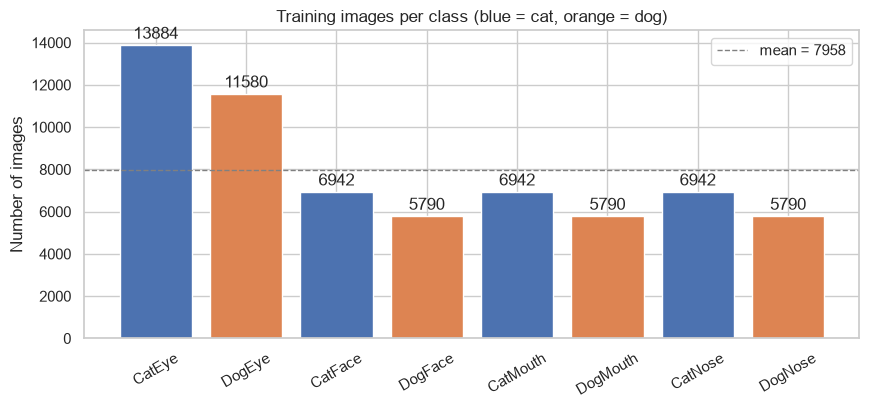

In [29]:
counts = train_df["label"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
class_table = pd.DataFrame({"images": counts, "percent": (100 * counts / counts.sum()).round(2)})
class_table = pd.concat([class_table, pd.DataFrame({"images": [counts.sum()], "percent": [100.0]}, index=["TOTAL"])])
display(class_table)

imbalance_ratio = counts.max() / max(counts.min(), 1)
print(f"Largest class : {counts.idxmax()} ({counts.max()})")
print(f"Smallest class: {counts.idxmin()} ({counts.min()})")
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")
print("Coefficient of variation of class sizes:", round(counts.std() / counts.mean(), 3))

# Species x part view
tmp = train_df.assign(species=train_df.label.str[:3], part=train_df.label.str[3:])
display(pd.crosstab(tmp.species, tmp.part, margins=True))

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in CLASS_NAMES]
bars = ax.bar(CLASS_NAMES, counts.values, color=colors)
ax.bar_label(bars, padding=2)
ax.axhline(counts.mean(), ls="--", c="grey", lw=1, label=f"mean = {counts.mean():.0f}")
ax.set_title("Training images per class (blue = cat, orange = dog)")
ax.set_ylabel("Number of images"); ax.legend()
plt.xticks(rotation=30); savefig("01_class_distribution"); plt.show()

In [30]:
# Automatic verdict that can be quoted in the report
if imbalance_ratio < 1.5:
    BALANCE_NOTE = "roughly balanced (max/min < 1.5) - plain cross-entropy and accuracy are appropriate"
elif imbalance_ratio < 3:
    BALANCE_NOTE = "mildly imbalanced - use a stratified split and report macro-F1 alongside accuracy"
else:
    BALANCE_NOTE = "clearly imbalanced - stratify, report macro-F1, and consider class-weighted loss"
USE_CLASS_WEIGHTS = imbalance_ratio >= 3
print("Dataset is", BALANCE_NOTE)
print("Use class-weighted loss:", USE_CLASS_WEIGHTS)

Dataset is mildly imbalanced - use a stratified split and report macro-F1 alongside accuracy
Use class-weighted loss: False


**Observation.** The two *Eye* classes contain exactly twice as many images as the other classes of the same species (CatEye = 2 × CatFace, DogEye = 2 × DogFace), and every cat part class has the same count, as does every dog part class. This means the crops were produced from whole-face photos: each face gives **one face, two eye, one mouth and one nose crop**. The imbalance is therefore *structural* (≈ 2.4 : 1 between the largest and smallest class) and the hidden test set was most likely produced the same way, so the class prior is kept (no re-weighting), and macro-F1 is reported alongside accuracy.

A second consequence: crops of the *same animal* (e.g. its eye and its face) can fall into both the training and the validation split. The ids are shuffled and there is no source-photo id, so this cannot be fully controlled — it is a limitation discussed in Section 6.

### 1.4 Representative sample images from each class

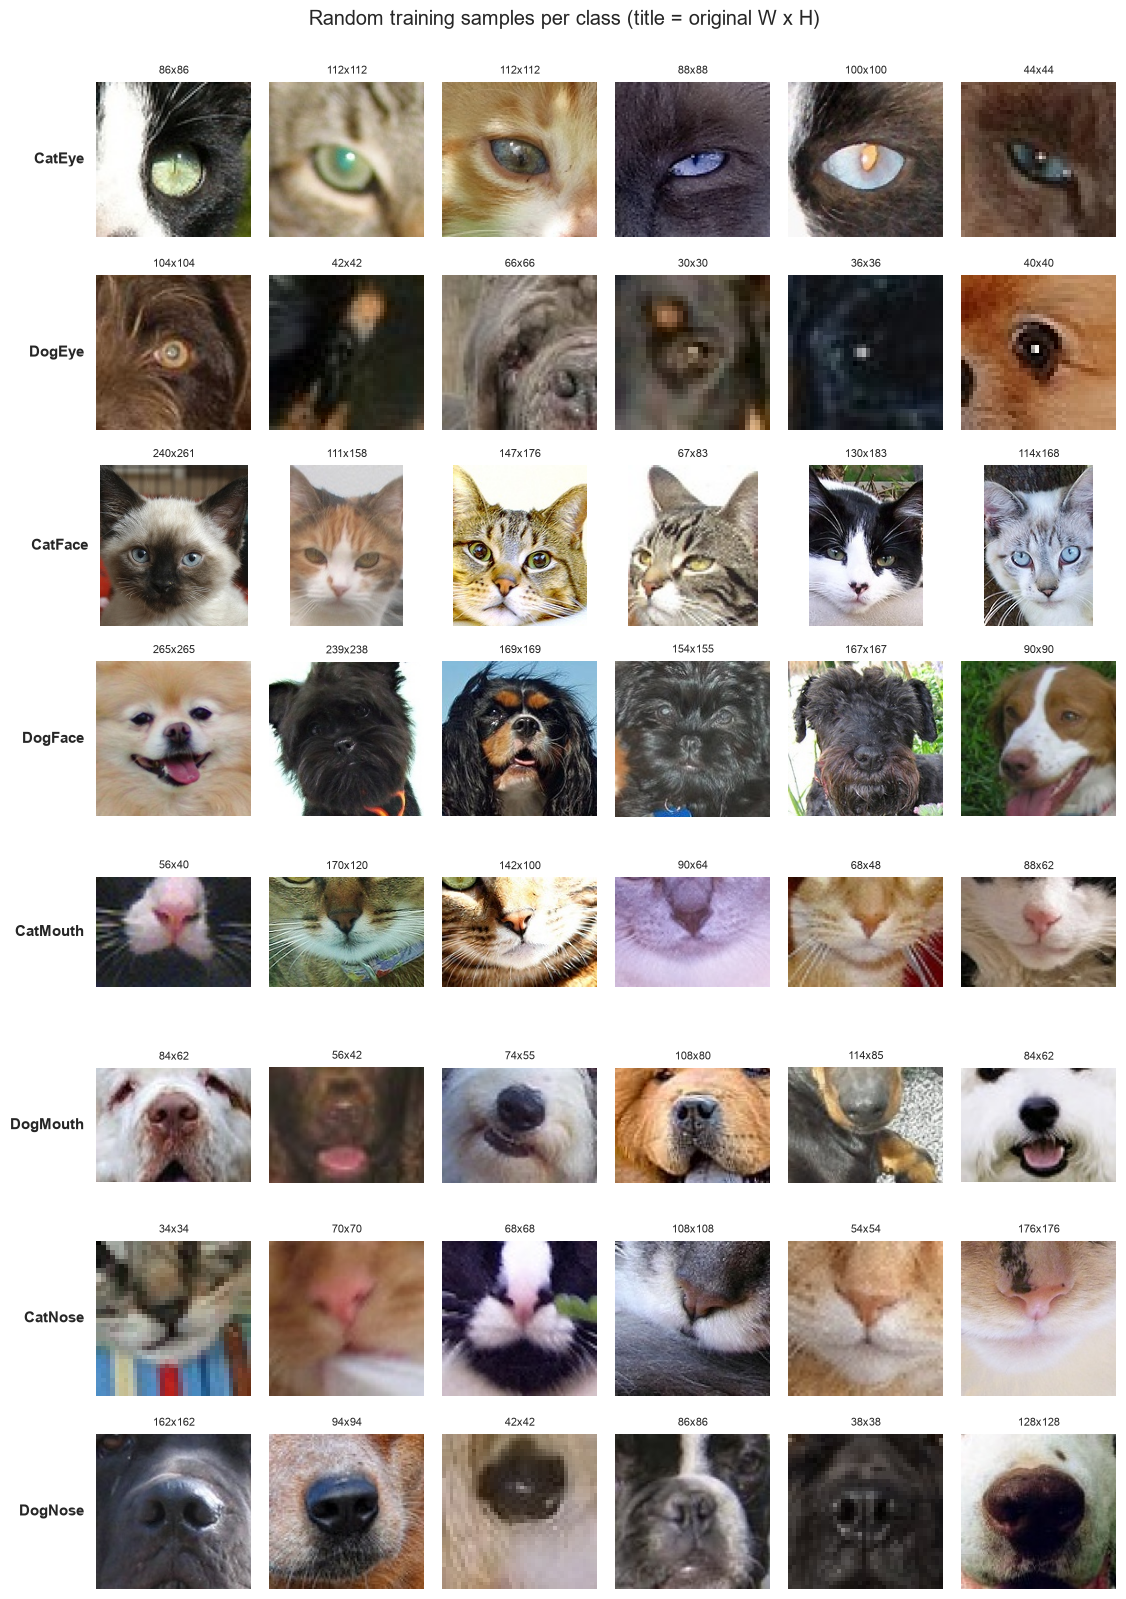

In [31]:
N_PER_CLASS = 6
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASS_NAMES), N_PER_CLASS, figsize=(N_PER_CLASS * 1.9, len(CLASS_NAMES) * 2.0))
for r, cls in enumerate(CLASS_NAMES):
    paths = train_df.loc[train_df.label == cls, "filepath"].values
    for c, p in enumerate(rng.choice(paths, size=min(N_PER_CLASS, len(paths)), replace=False)):
        with Image.open(p) as im:
            axes[r, c].imshow(im.convert("RGB"))
            axes[r, c].set_title(f"{im.size[0]}x{im.size[1]}", fontsize=8)
        axes[r, c].axis("off")
    axes[r, 0].text(-0.08, 0.5, cls, transform=axes[r, 0].transAxes, ha="right", va="center",
                    fontsize=11, fontweight="bold")
plt.suptitle("Random training samples per class (title = original W x H)", y=1.0)
plt.tight_layout(); savefig("02_samples_per_class"); plt.show()

### 1.5 Data quality checks
Every training and test image is opened once to collect: whether it decodes (corrupt / truncated files), size, colour mode, file format, an MD5 hash (exact duplicates), a perceptual *difference hash* (near-duplicates), a blur score (variance of the Laplacian) and mean brightness. Results are cached in `outputs/image_stats.csv`.

In [32]:
STATS_CSV = OUT_DIR / "image_stats.csv"
all_paths = list(train_df.filepath) + ([] if test_df is None else list(test_df.filepath))

if STATS_CSV.exists():
    stats = pd.read_csv(STATS_CSV)
    if set(stats.filepath) != set(all_paths):
        stats = None
else:
    stats = None

if stats is None:
    with ThreadPoolExecutor(max_workers=8) as ex:
        rows = list(tqdm(ex.map(L.inspect_image, all_paths), total=len(all_paths), desc="Inspecting images"))
    stats = pd.DataFrame(rows)
    stats.to_csv(STATS_CSV, index=False)

stats["split"] = np.where(stats.filepath.isin(set(train_df.filepath)), "train", "test")
stats = stats.merge(train_df, on="filepath", how="left")
stats["aspect"] = stats.width / stats.height
print("Images inspected:", len(stats))

Images inspected: 93103


In [33]:
# --- Corrupted / unreadable files ---
bad = stats[~stats.ok]
print(f"Corrupted / unreadable files: {len(bad)}")
display(bad[["filepath", "split", "error"]].head(20))

# --- Colour modes and file formats ---
ok = stats[stats.ok]
display(pd.crosstab(ok["mode"], ok["split"]).rename_axis("colour mode"))
display(pd.crosstab(ok["format"], ok["split"]).rename_axis("file format"))

# --- Image size statistics ---
print("\nImage size summary (pixels):")
display(ok.groupby("split")[["width", "height", "aspect", "file_kb"]].describe().T.round(1))
print("Distinct (width, height) combinations:", ok.groupby(["width", "height"]).ngroups)

Corrupted / unreadable files: 0


,filepath,split,error


split,test,train
colour mode,,
RGB,29443,63660


split,test,train
file format,,
JPEG,29443,63660



Image size summary (pixels):


split             test    train
width   count  29443.0  63660.0
        mean     113.5    113.1
        std      100.7     98.5
        min        8.0      4.0
        25%       53.0     54.0
        50%       82.0     84.0
        75%      140.0    138.0
        max     1832.0   2219.0
height  count  29443.0  63660.0
        mean     109.7    109.7
        std      103.7    101.9
        min        9.0      4.0
        25%       50.0     50.0
        50%       80.0     80.0
        75%      128.0    130.0
        max     1978.0   2219.0
aspect  count  29443.0  63660.0
        mean       1.1      1.1
        std        0.2      0.2
        min        0.3      0.4
        25%        1.0      1.0
        50%        1.0      1.0
        75%        1.2      1.0
        max        4.4     10.0
file_kb count  29443.0  63660.0
        mean      10.7     10.6
        std       25.9     24.1
        min        0.7      0.6
        25%        2.1      2.2
        50%        4.1      4.2
        75%        9.4      9.6
        max     1176.0   1233.1

Distinct (width, height) combinations: 14347


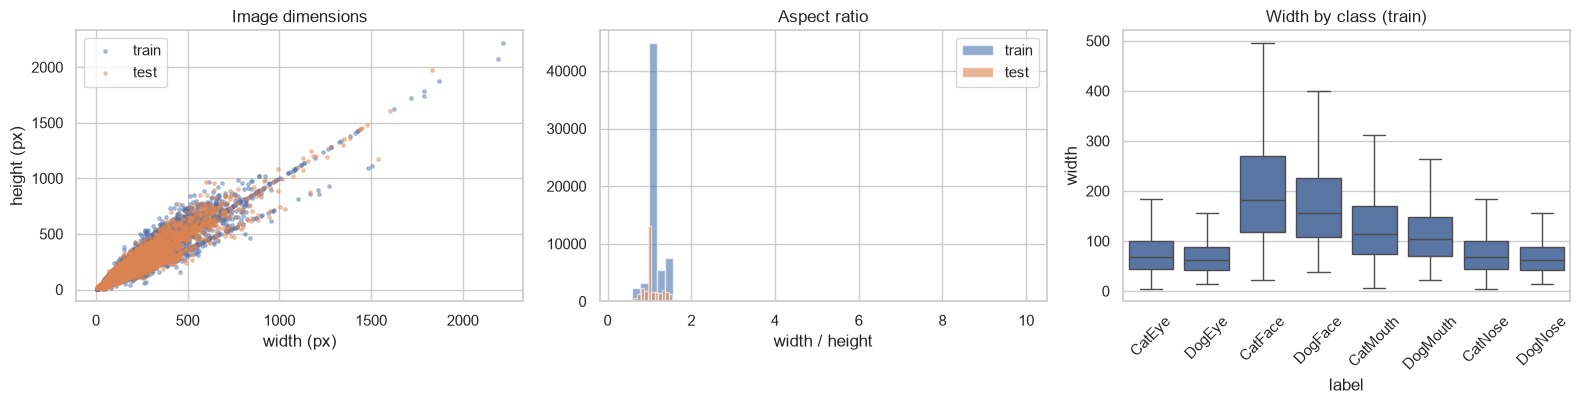

Very small images (< 64 px on a side): 35595  -> these will be heavily up-sampled to 224px


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for split, c in [("train", "#4C72B0"), ("test", "#DD8452")]:
    s = ok[ok.split == split]
    axes[0].scatter(s.width, s.height, s=6, alpha=0.4, c=c, label=split)
    axes[1].hist(s.aspect, bins=50, alpha=0.6, color=c, label=split)
axes[0].set_xlabel("width (px)"); axes[0].set_ylabel("height (px)"); axes[0].set_title("Image dimensions"); axes[0].legend()
axes[1].set_xlabel("width / height"); axes[1].set_title("Aspect ratio"); axes[1].legend()
sns.boxplot(data=ok[ok.split == "train"], x="label", y="width", order=CLASS_NAMES, ax=axes[2], showfliers=False)
axes[2].set_title("Width by class (train)"); axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("03_image_sizes"); plt.show()

small = ok[(ok.width < 64) | (ok.height < 64)]
print(f"Very small images (< 64 px on a side): {len(small)}  -> these will be heavily up-sampled to {IMG_SIZE}px")

In [35]:
# --- Shape of the crops per class, and train vs test ---
trs = ok[ok.split == "train"]
shape_tbl = trs.groupby("label").agg(images=("width", "size"),
                                     square_pct=("aspect", lambda a: 100 * (a == 1).mean()),
                                     median_w=("width", "median"), median_h=("height", "median"),
                                     median_aspect=("aspect", "median"),
                                     pct_below_64px=("width", lambda w: 100 * (w < 64).mean())).reindex(CLASS_NAMES)
display(shape_tbl.round(1))

bins = [0, 0.8, 0.95, 1.0, 1.05, 1.25, 10]
aspect_tbl = pd.crosstab(pd.cut(ok.aspect, bins, include_lowest=True), ok.split, normalize="columns").mul(100).round(1)
display(aspect_tbl.rename_axis("aspect ratio (w/h)"))
print(f"Exactly square crops: train {100*(ok[ok.split=='train'].aspect==1).mean():.1f}%  |  "
      f"test {100*(ok[ok.split=='test'].aspect==1).mean():.1f}%")

,images,square_pct,median_w,median_h,median_aspect,pct_below_64px
label,,,,,,
CatEye,13884,99.9,68.0,68.0,1.0,45.6
DogEye,11580,99.9,62.0,62.0,1.0,52.5
CatFace,6942,0.6,182.0,215.0,0.8,4.5
DogFace,5790,61.7,155.0,155.0,1.0,2.5
CatMouth,6942,0.0,114.0,80.0,1.4,16.9
DogMouth,5790,0.0,104.0,77.0,1.4,16.2
CatNose,6942,98.9,68.0,68.0,1.0,45.6
DogNose,5790,99.9,62.0,62.0,1.0,52.5


split,test,train
aspect ratio (w/h),,
"(-0.001, 0.8]",8.1,4.5
"(0.8, 0.95]",12.1,4.0
"(0.95, 1.0]",38.8,67.8
"(1.0, 1.05]",6.2,2.2
"(1.05, 1.25]",13.3,1.1
"(1.25, 10.0]",21.4,20.3


Exactly square crops: train 65.5%  |  test 32.8%


**Observations on crop shape.** Eye and nose crops in the training set are almost always exactly square (≈ 62–68 px), mouth crops are always landscape (aspect ≈ 1.4), cat faces are portrait and dog faces mixed. So the *shape* of a training crop is itself a strong hint about its class — a shortcut the network could learn because resizing to 224 × 224 squashes non-square crops in a recognisable way. The **test set has many more slightly non-square crops** than the training set (compare the two columns above), i.e. there is a mild train → test distribution shift in crop geometry. To stop the model relying on exact proportions, training augmentation includes aspect-ratio jitter (`RandomResizedCrop` with ratio 0.75–1.33), and the gap between validation accuracy and the Kaggle score is checked in Section 5.4.

Blur score (variance of Laplacian): median 1300.0, 2nd percentile 72.4


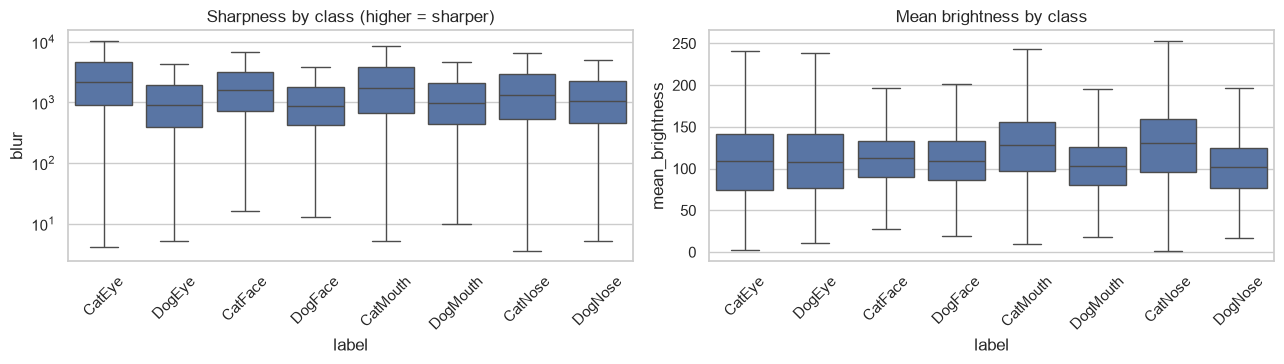

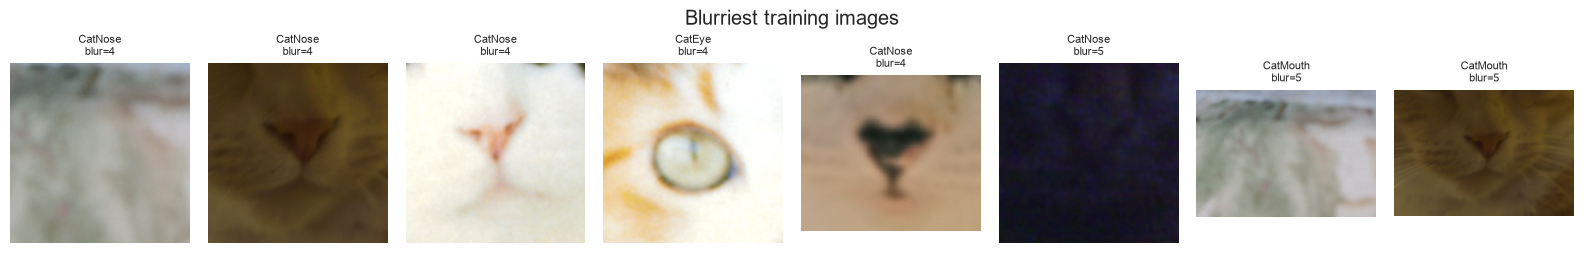

In [36]:
# --- Blur and brightness ---
blur_thr = ok.blur.quantile(0.02)
print(f"Blur score (variance of Laplacian): median {ok.blur.median():.1f}, 2nd percentile {blur_thr:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=ok[ok.split == "train"], x="label", y="blur", order=CLASS_NAMES, ax=axes[0], showfliers=False)
axes[0].set_yscale("log"); axes[0].set_title("Sharpness by class (higher = sharper)"); axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=ok[ok.split == "train"], x="label", y="mean_brightness", order=CLASS_NAMES, ax=axes[1], showfliers=False)
axes[1].set_title("Mean brightness by class"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("04_blur_brightness"); plt.show()

blurriest = ok[ok.split == "train"].nsmallest(8, "blur")
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, (_, r) in zip(axes, blurriest.iterrows()):
    with Image.open(r.filepath) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{r.label}\nblur={r.blur:.0f}", fontsize=8); ax.axis("off")
plt.suptitle("Blurriest training images"); plt.tight_layout(); savefig("05_blurriest"); plt.show()

Exact duplicate groups in train: 15 (30 files)
  ...of which have CONFLICTING labels: 0
Train images that also appear (byte-identical) in test: 0
Largest near-duplicate group: 72 images
Near-duplicate groups in train: 325 covering 805 images
  ...near-duplicate groups with conflicting labels: 33


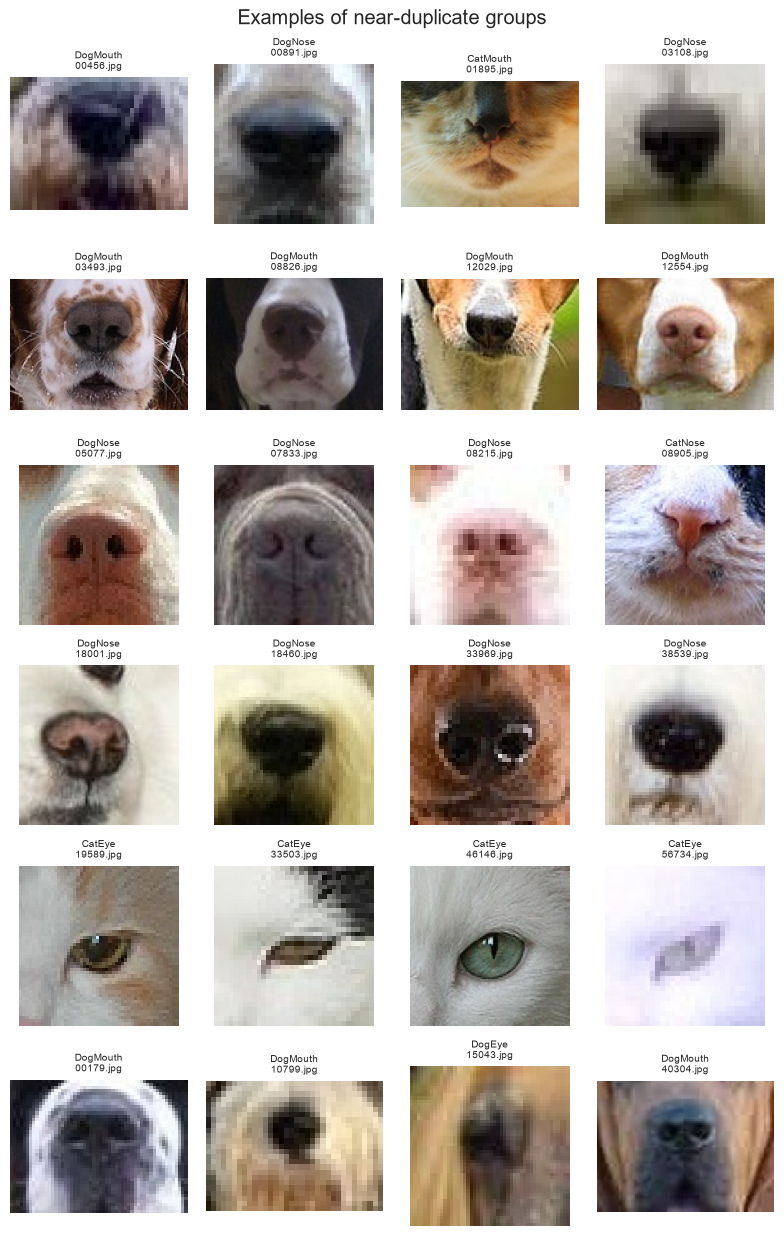

In [37]:
# --- Exact duplicates (identical bytes) ---
tr = stats[(stats.split == "train") & stats.ok].copy()
dup_md5 = tr[tr.duplicated("md5", keep=False)].sort_values("md5")
n_dup_groups = dup_md5.md5.nunique()
conflict = dup_md5.groupby("md5").label.nunique()
conflict_md5 = set(conflict[conflict > 1].index)
print(f"Exact duplicate groups in train: {n_dup_groups} ({len(dup_md5)} files)")
print(f"  ...of which have CONFLICTING labels: {len(conflict_md5)}")

te = stats[(stats.split == "test") & stats.ok]
overlap_md5 = set(tr.md5) & set(te.md5)
print(f"Train images that also appear (byte-identical) in test: {len(overlap_md5)}")

# --- Near duplicates (perceptual hash, Hamming distance <= 3 of 64 bits) ---
tr["dup_group"] = L.near_duplicate_groups(tr.dhash.astype("uint64").tolist(), max_dist=3)
grp_sizes = tr.dup_group.value_counts()
print("Largest near-duplicate group:", int(grp_sizes.max()), "images")
near = tr[tr.dup_group.map(grp_sizes) > 1]
print(f"Near-duplicate groups in train: {(grp_sizes > 1).sum()} covering {len(near)} images")
near_conflict = near.groupby("dup_group").label.nunique()
print(f"  ...near-duplicate groups with conflicting labels: {(near_conflict > 1).sum()}")

# Show a few near-duplicate groups
show_groups = grp_sizes[grp_sizes > 1].index[:6]
if len(show_groups):
    fig, axes = plt.subplots(len(show_groups), 4, figsize=(8, 2.1 * len(show_groups)), squeeze=False)
    for r, g in enumerate(show_groups):
        members = tr[tr.dup_group == g].head(4)
        for c in range(4):
            axes[r, c].axis("off")
            if c < len(members):
                m = members.iloc[c]
                with Image.open(m.filepath) as im:
                    axes[r, c].imshow(im.convert("RGB"))
                axes[r, c].set_title(f"{m.label}\n{Path(m.filepath).name[:18]}", fontsize=7)
    plt.suptitle("Examples of near-duplicate groups"); plt.tight_layout(); savefig("06_near_duplicates"); plt.show()

In [38]:
quality_summary = {
    "train_images": int((stats.split == "train").sum()),
    "test_images": int((stats.split == "test").sum()),
    "corrupted": int((~stats.ok).sum()),
    "distinct_sizes": int(ok.groupby(["width", "height"]).ngroups),
    "non_rgb_images": int((ok["mode"] != "RGB").sum()),
    "very_small_images": int(len(small)),
    "exact_duplicate_groups_train": int(n_dup_groups),
    "exact_duplicates_conflicting_labels": int(len(conflict_md5)),
    "train_test_exact_overlap": int(len(overlap_md5)),
    "near_duplicate_groups_train": int((grp_sizes > 1).sum()),
    "near_duplicate_groups_conflicting": int((near_conflict > 1).sum()),
    "imbalance_ratio": round(float(imbalance_ratio), 3),
}
display(pd.Series(quality_summary, name="value").to_frame())

,value
train_images,63660.000
test_images,29443.000
corrupted,0.000
distinct_sizes,14347.000
non_rgb_images,0.000
very_small_images,35595.000
exact_duplicate_groups_train,15.000
exact_duplicates_conflicting_labels,0.000
train_test_exact_overlap,0.000
near_duplicate_groups_train,325.000


### 1.6 How the data will be used

* **Training set (labelled)** → cleaned (corrupt files and label-conflicting duplicates removed, exact duplicates de-duplicated), then split **80 / 20** into *train* and *validation* with `StratifiedGroupKFold`:
  * *stratified* so each class keeps the same proportion in both parts;
  * *grouped* by near-duplicate cluster so copies of the same picture can never be on both sides of the split (otherwise validation accuracy would be inflated by memorisation — data leakage).
* **Train part** → used to fit model weights (with augmentation).
* **Validation part** → never trained on; used for early stopping, model / hyper-parameter selection and all reported metrics.
* **Test set (unlabelled)** → only used once at the end to produce `submission.csv`; scored by Kaggle on the public leaderboard (and later the private one).

## 2. Data preprocessing and pipeline preparation

### 2.1 Cleaning and label encoding

In [39]:
clean = tr.copy()
n0 = len(clean)
clean = clean[~clean.md5.isin(conflict_md5)]                 # ambiguous: same image, different labels
clean = clean.drop_duplicates("md5", keep="first")            # identical copies add no information
print(f"Corrupted removed: {int((~stats[stats.split=='train'].ok).sum())}")
print(f"Removed {n0 - len(clean)} duplicate / conflicting files -> {len(clean)} training images remain")

# Label encoding: class name <-> integer index (alphabetical order of CLASS_NAMES list is NOT required,
# we simply keep the fixed order above so indices are stable and documented).
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
clean["y"] = clean.label.map(class_to_idx).astype(int)
with open(OUT_DIR / "label_map.json", "w") as f:
    json.dump(class_to_idx, f, indent=2)
print("Label encoding:", class_to_idx)

Corrupted removed: 0
Removed 15 duplicate / conflicting files -> 63645 training images remain
Label encoding: {'CatEye': 0, 'DogEye': 1, 'CatFace': 2, 'DogFace': 3, 'CatMouth': 4, 'DogMouth': 5, 'CatNose': 6, 'DogNose': 7}


### 2.2 Train / validation split (stratified, grouped — leakage-free)

In [40]:
n_splits = int(round(1 / VAL_FRACTION))
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(clean, clean.y, groups=clean.dup_group))
train_split = clean.iloc[tr_idx].reset_index(drop=True)
val_split = clean.iloc[va_idx].reset_index(drop=True)
if QUICK_RUN:   # tiny stratified subset just to check that the code runs end-to-end
    train_split = train_split.groupby("label").head(16).reset_index(drop=True)
    val_split = val_split.groupby("label").head(8).reset_index(drop=True)

split_table = pd.DataFrame({
    "train": train_split.label.value_counts().reindex(CLASS_NAMES),
    "val": val_split.label.value_counts().reindex(CLASS_NAMES),
})
split_table["val %"] = (100 * split_table.val / (split_table.train + split_table.val)).round(1)
display(split_table)
print(f"Train: {len(train_split)}  |  Validation: {len(val_split)}")

# Leakage checks
assert not set(train_split.dup_group) & set(val_split.dup_group), "near-duplicate group in both splits!"
assert not set(train_split.md5) & set(val_split.md5), "identical image in both splits!"
print("Leakage checks passed: no shared files or near-duplicate groups between train and validation.")

train_split.to_csv(OUT_DIR / "train_split.csv", index=False)
val_split.to_csv(OUT_DIR / "val_split.csv", index=False)

,train,val,val %
label,,,
CatEye,11101,2776,20.0
DogEye,9260,2316,20.0
CatFace,5554,1388,20.0
DogFace,4631,1157,20.0
CatMouth,5553,1388,20.0
DogMouth,4632,1158,20.0
CatNose,5553,1388,20.0
DogNose,4632,1158,20.0


Train: 50916  |  Validation: 12729
Leakage checks passed: no shared files or near-duplicate groups between train and validation.


### 2.3 Resizing, normalisation and augmentation

* **Resize** every image to **224 × 224** (the resolution the ImageNet-pretrained backbones were trained at). Images vary in size, so a fixed size is required to batch them.
* **Rescale** pixels from [0, 255] to [0, 1] (`ToTensor`) and **normalise** with the ImageNet channel mean / std, because the pretrained weights expect that input distribution.
* **Augmentation (training only)** — label-preserving transformations that simulate natural variation in the photos: random resized crop (75–100 % of the area, aspect ratio 0.75–1.33 to cover the more varied crop shapes of the test set), horizontal flip, ±15° rotation, colour jitter, occasional greyscale and random erasing (simulates occlusion). Vertical flips are *not* used because upside-down faces do not occur in the data.
* **Validation and test** use the *same deterministic* transform (resize + normalise) so preprocessing is consistent.

TRAIN transform:
 Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.75, 1.0), ratio=(0.75, 1.33), interpolation=bicubic, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.75, 1.25), contrast=(0.75, 1.25), saturation=(0.75, 1.25), hue=(-0.03, 0.03))
    RandomGrayscale(p=0.05)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
    RandomErasing(p=0.2, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=0, inplace=False)
) 

VAL / TEST transform:
 Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


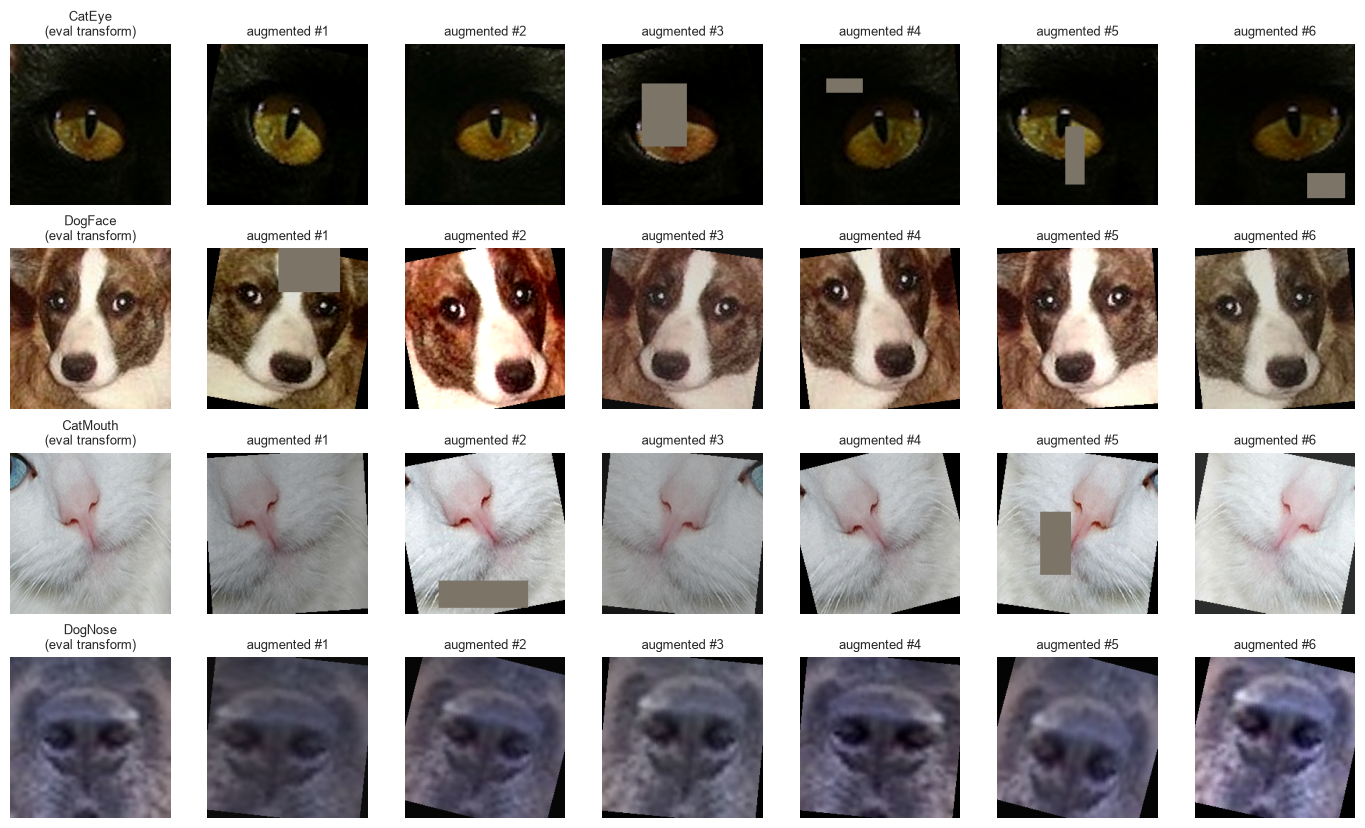

In [41]:
train_tf, eval_tf = L.build_transforms(IMG_SIZE, augment=True)
print("TRAIN transform:\n", train_tf, "\n\nVAL / TEST transform:\n", eval_tf)

# Visualise augmentation on one image per class
fig, axes = plt.subplots(4, 7, figsize=(14, 8.4))
for r, cls in enumerate(["CatEye", "DogFace", "CatMouth", "DogNose"]):
    p = train_split[train_split.label == cls].filepath.iloc[0]
    with Image.open(p) as im:
        img = im.convert("RGB")
    axes[r, 0].imshow(L.denormalize(eval_tf(img))); axes[r, 0].set_title(f"{cls}\n(eval transform)", fontsize=9)
    for c in range(1, 7):
        axes[r, c].imshow(L.denormalize(train_tf(img))); axes[r, c].set_title(f"augmented #{c}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); savefig("07_augmentation_examples"); plt.show()

### 2.4 Dataset objects and data loaders

In [42]:
def make_loaders(train_transform, batch_size=BATCH_SIZE):
    train_ds = L.ImageDataset(train_split.filepath, train_split.y, train_transform)
    val_ds = L.ImageDataset(val_split.filepath, val_split.y, eval_tf)
    return (L.make_loader(train_ds, batch_size, True, NUM_WORKERS, SEED, drop_last=True),
            L.make_loader(val_ds, batch_size * 2, False, min(NUM_WORKERS, 2), SEED))

train_loader, val_loader = make_loaders(train_tf)

if test_df is not None:
    test_ds = L.ImageDataset(test_df.filepath, None, eval_tf, ids=test_df.key)
    test_loader = L.make_loader(test_ds, BATCH_SIZE * 2, False, NUM_WORKERS, SEED, persistent=False)

xb, yb = next(iter(train_loader))
print("Batch tensor :", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype)
print(f"Pixel range after normalisation: [{xb.min():.2f}, {xb.max():.2f}]  mean {xb.mean():.3f}  std {xb.std():.3f}")
print("Batches per epoch: train", len(train_loader), "| val", len(val_loader))

# Class weights (inverse frequency) - only used if the dataset is clearly imbalanced
freq = train_split.y.value_counts().sort_index().values
class_weights = (len(train_split) / (len(CLASS_NAMES) * freq)).round(4)
print("Inverse-frequency class weights:", dict(zip(CLASS_NAMES, class_weights)))

Batch tensor : (64, 3, 224, 224) torch.float32 | labels: (64,) torch.int64
Pixel range after normalisation: [-2.12, 2.64]  mean -0.200  std 1.265
Batches per epoch: train 795 | val 100
Inverse-frequency class weights: {'CatEye': np.float64(0.5733), 'DogEye': np.float64(0.6873), 'CatFace': np.float64(1.1459), 'DogFace': np.float64(1.3743), 'CatMouth': np.float64(1.1461), 'DogMouth': np.float64(1.374), 'CatNose': np.float64(1.1461), 'DogNose': np.float64(1.374)}


## 3. Model selection and pipeline development

### 3.1 Choice of architecture
**Main model: EfficientNet-B0, ImageNet-pretrained, fine-tuned (transfer learning)** via the `timm` library.

*Why transfer learning?* The dataset is small relative to what is needed to learn visual features from scratch. A backbone pretrained on ImageNet (1.28 M images, which include many cats and dogs) already contains strong low-level (edges, textures, fur) and high-level (eyes, noses, snouts) features, so it converges faster and generalises better.

*Why EfficientNet-B0?* It is accurate for its size (≈ 5.3 M parameters, 0.39 GFLOPs at 224 px), trains quickly on a laptop GPU, and fits comfortably in GPU memory with batch size 32 and mixed precision.

**Architecture components**
* *Stem*: 3×3 conv (stride 2) + BatchNorm + SiLU.
* *Body*: 16 **MBConv** blocks (inverted residual bottlenecks with depth-wise convolutions) in 7 stages, each with a **Squeeze-and-Excitation** module that re-weights channels; stochastic depth for regularisation.
* *Head*: 1×1 conv to 1280 channels → global average pooling → dropout (p = 0.3) → **fully-connected layer 1280 → 8**.
* *Output*: 8 logits; **softmax** turns them into class probabilities (applied inside the cross-entropy loss during training and explicitly at prediction time).

| Setting | Value | Justification |
|---|---|---|
| Input size | 224 × 224 × 3 | native resolution of the pretrained weights |
| Output layer | Linear(1280 → 8) + softmax | one output per class, mutually exclusive classes |
| Loss | Cross-entropy with label smoothing 0.1 | standard for multi-class; smoothing reduces over-confidence |
| Optimiser | AdamW, weight decay 0.05 | adaptive LR + decoupled L2 regularisation |
| Learning rate | head 1e-3, backbone 1e-4 (discriminative), 1-epoch linear warm-up + cosine decay | small LR on pretrained layers avoids destroying learnt features |
| Batch size | 64 (32 on GPUs with < 7.5 GB) | good gradient estimate, fits laptop GPU memory |
| Epochs | up to 15, early stopping (patience 4 on val loss) | ~51 k training images, so few epochs are needed; best checkpoint kept |
| Mixed precision | yes (CUDA) | ≈ 2× faster, half the memory |

To justify the choice empirically, the same pipeline also trains comparison models (Section 3.3).

In [43]:
demo = L.build_model(FINAL_ARCH, len(CLASS_NAMES), pretrained=False)
total, trainable = L.count_params(demo)
print(f"{FINAL_ARCH}: {total/1e6:.2f} M parameters")
print("Classifier head:", demo.get_classifier())
with torch.no_grad():
    out = demo(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
print("Input (2, 3, 224, 224) -> output", tuple(out.shape), "(one logit per class)")

cnn = L.SimpleCNN(len(CLASS_NAMES))
print(f"\nBaseline SimpleCNN: {L.count_params(cnn)[0]/1e6:.2f} M parameters\n", cnn)
del demo, cnn

efficientnet_b0: 4.02 M parameters
Classifier head: Linear(in_features=1280, out_features=8, bias=True)
Input (2, 3, 224, 224) -> output (2, 8) (one logit per class)

Baseline SimpleCNN: 1.18 M parameters
 SimpleCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

### 3.2 Experiments
Each experiment changes one thing so its effect can be measured on the same validation split:

| # | Name | What it tests |
|---|---|---|
| E1 | `cnn_scratch` | custom 8-layer CNN trained from scratch (baseline, no pretraining) |
| E2 | `effb0_frozen` | pretrained EfficientNet-B0, backbone **frozen**, only the head trained (feature extraction) |
| E3 | `effb0_ft_noaug` | full fine-tuning **without** augmentation / label smoothing (shows overfitting) |
| E4 | `effb0_ft` | **full fine-tuning + augmentation + label smoothing** (main model) |
| E5 | `convnext_tiny_ft` | larger, more modern backbone with the E4 recipe (optional, slower) |

`RUN_ABLATIONS = False` trains only E4; `RUN_CONVNEXT = True` adds E5.

In [44]:
EXPERIMENTS = [
    L.TrainConfig("cnn_scratch", "simple_cnn", pretrained=False, epochs=12, lr=1e-3, patience=4,
                  weight_decay=1e-4, label_smoothing=0.1),
    L.TrainConfig("effb0_frozen", FINAL_ARCH, freeze_backbone=True, epochs=6, lr=1e-3, patience=3),
    L.TrainConfig("effb0_ft_noaug", FINAL_ARCH, epochs=12, lr=1e-3, backbone_lr_mult=0.1, patience=3,
                  label_smoothing=0.0, drop_rate=0.0, extra={"augment": False}),
    L.TrainConfig("effb0_ft", FINAL_ARCH, epochs=15, lr=1e-3, backbone_lr_mult=0.1,
                  label_smoothing=0.1, drop_rate=0.3),
    L.TrainConfig("convnext_tiny_ft", "convnext_tiny.fb_in22k_ft_in1k", epochs=10, lr=5e-4,
                  backbone_lr_mult=0.1, label_smoothing=0.1, drop_rate=0.3),
]
MAIN_EXPERIMENT = "effb0_ft"
to_run = [e for e in EXPERIMENTS
          if e.name == MAIN_EXPERIMENT
          or (RUN_ABLATIONS and e.name in ("cnn_scratch", "effb0_frozen", "effb0_ft_noaug"))
          or (RUN_CONVNEXT and e.name == "convnext_tiny_ft")]
for e in to_run:
    e.use_class_weights = USE_CLASS_WEIGHTS
    if QUICK_RUN:
        e.epochs, e.patience = 2, 2
pd.DataFrame([vars(e) for e in to_run]).drop(columns=["extra"])

,name,arch,pretrained,freeze_backbone,epochs,lr,backbone_lr_mult,weight_decay,label_smoothing,warmup_epochs,patience,drop_rate,use_class_weights
0,cnn_scratch,simple_cnn,False,False,12,0.001,0.1,0.0001,0.1,1,4,0.3,False
1,effb0_frozen,efficientnet_b0,True,True,6,0.001,0.1,0.0500,0.1,1,3,0.3,False
2,effb0_ft_noaug,efficientnet_b0,True,False,12,0.001,0.1,0.0500,0.0,1,3,0.0,False
3,effb0_ft,efficientnet_b0,True,False,15,0.001,0.1,0.0500,0.1,1,4,0.3,False


### 3.3 Training
Each run saves its best checkpoint (`outputs/<name>_best.pt`), the per-epoch history (`*_history.csv`) and a summary (`*_summary.json`). Re-running the cell skips experiments that already finished (checkpoint + history + summary present) unless `RETRAIN = True`; an interrupted run is trained again.

In [45]:
RETRAIN = False
noaug_loader = None
models, histories, summaries = {}, {}, {}

for cfg in to_run:
    ckpt = OUT_DIR / f"{cfg.name}_best.pt"
    finished = all((OUT_DIR / f"{cfg.name}{x}").exists() for x in ("_best.pt", "_history.csv", "_summary.json"))
    if finished and not RETRAIN and not QUICK_RUN:          # only re-use runs that completed
        print(f"[{cfg.name}] loading existing checkpoint")
        m = L.build_model(cfg.arch, len(CLASS_NAMES), pretrained=False, drop_rate=cfg.drop_rate).to(device)
        m.load_state_dict(torch.load(ckpt, map_location=device))
        models[cfg.name] = m
        histories[cfg.name] = pd.read_csv(OUT_DIR / f"{cfg.name}_history.csv")
        summaries[cfg.name] = json.load(open(OUT_DIR / f"{cfg.name}_summary.json"))
        continue
    L.seed_everything(SEED)                     # same initial conditions for every experiment
    if cfg.extra.get("augment", True):
        tl = train_loader
    else:
        if noaug_loader is None:
            noaug_loader, _ = make_loaders(eval_tf)
        tl = noaug_loader
    m, h, s = L.fit(cfg, tl, val_loader, len(CLASS_NAMES), device, OUT_DIR,
                    class_weights=class_weights, max_batches=MAX_BATCHES)
    models[cfg.name], histories[cfg.name], summaries[cfg.name] = m, h, s
    if tl is noaug_loader:              # free the extra worker processes once E3 is done
        del tl
        noaug_loader = None
    if device.type == "cuda":
        torch.cuda.empty_cache()

[cnn_scratch] loading existing checkpoint
[effb0_frozen] loading existing checkpoint
[effb0_ft_noaug] loading existing checkpoint
[effb0_ft] arch=efficientnet_b0 params=4.02M trainable=4.02M head_lr=0.001 body_lr=0.0001
  ep 01 | train loss 1.8478 acc 0.6282 | val loss 0.2511 acc 0.9434 | lr 1.00e-03 | 153s *
  ep 02 | train loss 0.6312 acc 0.9507 | val loss 0.1448 acc 0.9779 | lr 9.88e-04 | 128s *
  ep 03 | train loss 0.5568 acc 0.9742 | val loss 0.1463 acc 0.9811 | lr 9.51e-04 | 128s 
  ep 04 | train loss 0.5306 acc 0.9804 | val loss 0.1310 acc 0.9873 | lr 8.92e-04 | 128s *
  ep 05 | train loss 0.5178 acc 0.9837 | val loss 0.1232 acc 0.9869 | lr 8.14e-04 | 128s *
  ep 06 | train loss 0.5090 acc 0.9863 | val loss 0.1187 acc 0.9901 | lr 7.20e-04 | 140s *
  ep 07 | train loss 0.5033 acc 0.9883 | val loss 0.1281 acc 0.9866 | lr 6.15e-04 | 130s 
  ep 08 | train loss 0.4971 acc 0.9904 | val loss 0.1179 acc 0.9899 | lr 5.05e-04 | 129s *
  ep 09 | train loss 0.4944 acc 0.9908 | val loss 0.11

## 4. Training strategy and overfitting / underfitting management

### 4.1 Learning curves
Note: training accuracy is measured on *augmented* images with dropout active, while validation uses clean images in eval mode — so a model with strong regularisation can show validation accuracy *above* training accuracy. That is expected, not an error.

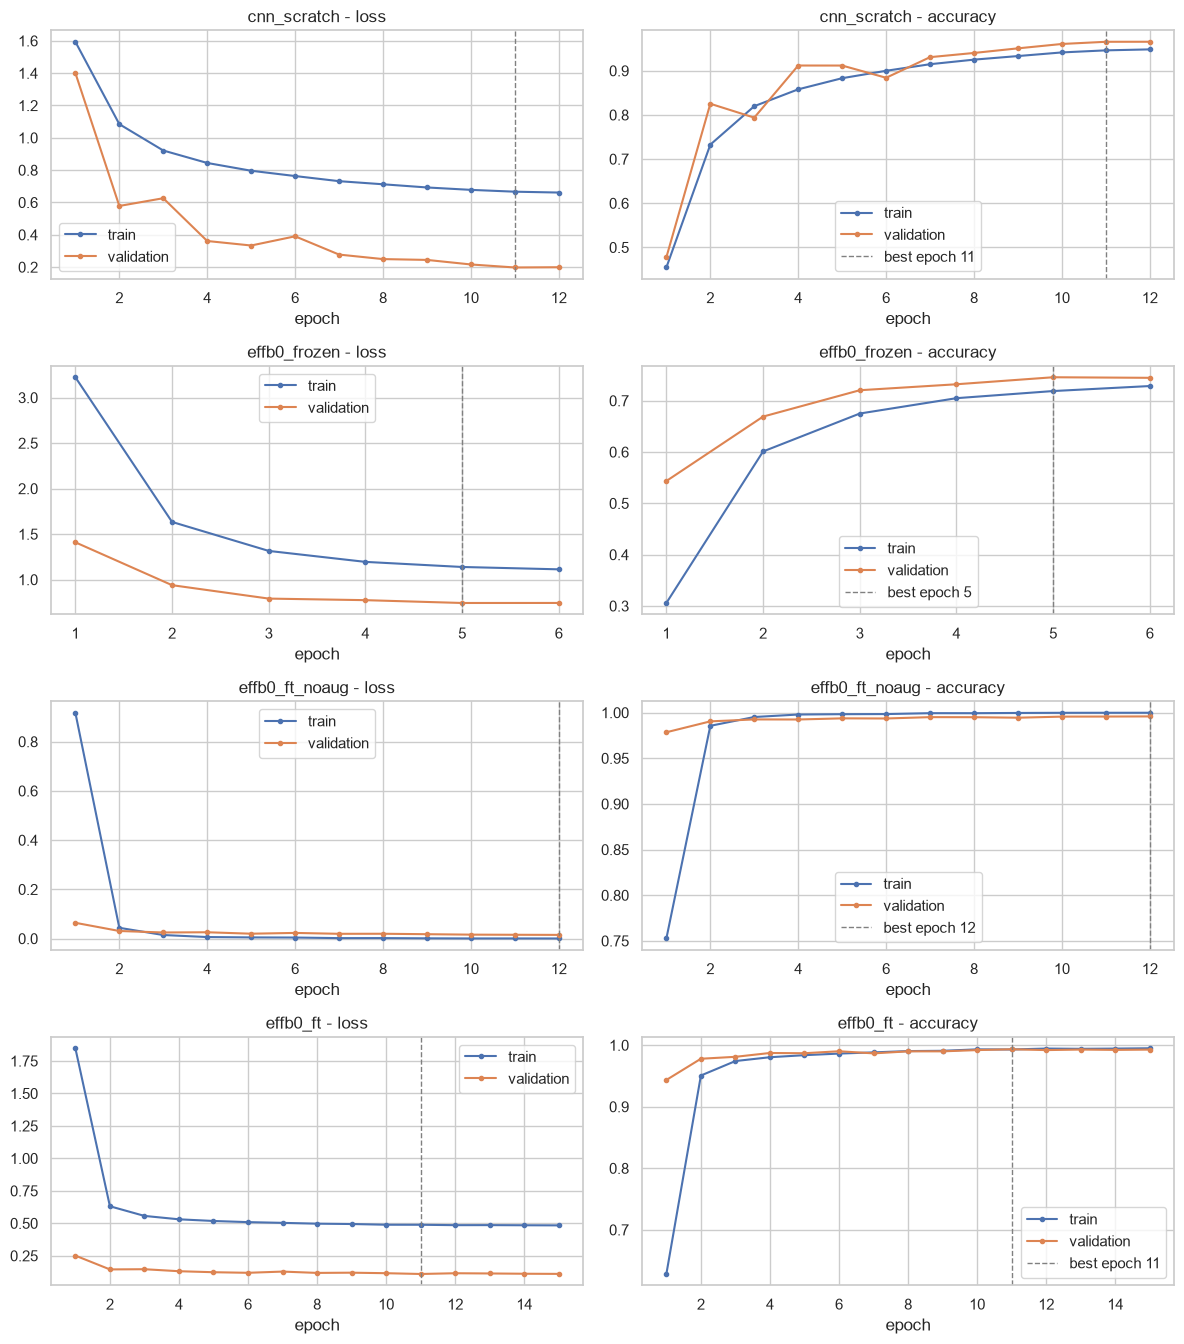

In [46]:
def plot_curves(name, hist, ax_loss, ax_acc):
    best = hist.loc[hist.val_loss.idxmin()]
    ax_loss.plot(hist.epoch, hist.train_loss, "o-", ms=3, label="train")
    ax_loss.plot(hist.epoch, hist.val_loss, "o-", ms=3, label="validation")
    ax_loss.axvline(best.epoch, ls="--", c="grey", lw=1)
    ax_loss.set_title(f"{name} - loss"); ax_loss.set_xlabel("epoch"); ax_loss.legend()
    ax_acc.plot(hist.epoch, hist.train_acc, "o-", ms=3, label="train")
    ax_acc.plot(hist.epoch, hist.val_acc, "o-", ms=3, label="validation")
    ax_acc.axvline(best.epoch, ls="--", c="grey", lw=1, label=f"best epoch {int(best.epoch)}")
    ax_acc.set_title(f"{name} - accuracy"); ax_acc.set_xlabel("epoch"); ax_acc.legend()

n = len(histories)
fig, axes = plt.subplots(n, 2, figsize=(12, 3.4 * n), squeeze=False)
for i, (name, h) in enumerate(histories.items()):
    plot_curves(name, h, axes[i, 0], axes[i, 1])
plt.tight_layout(); savefig("08_learning_curves_all"); plt.show()

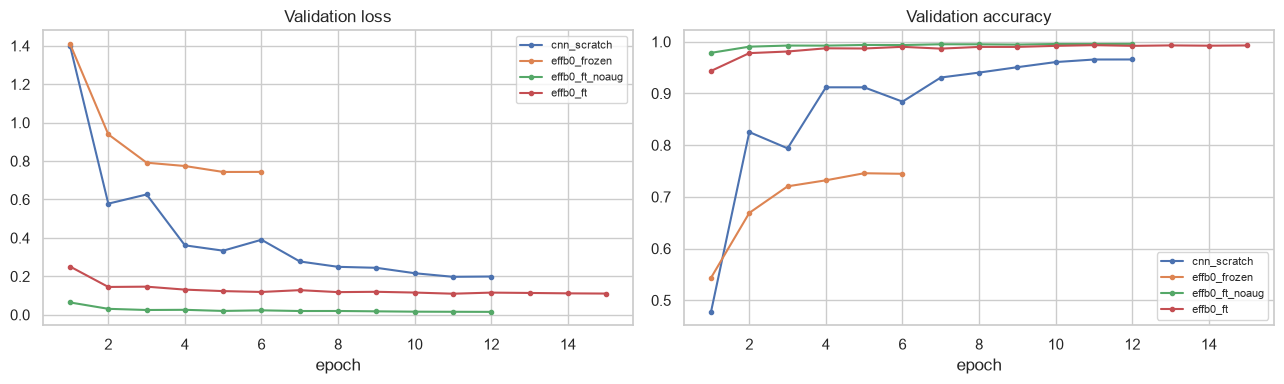

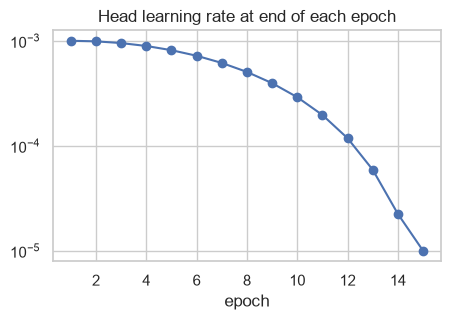

In [47]:
# Overlay of validation loss / accuracy across experiments
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(h.epoch, h.val_loss, "o-", ms=3, label=name)
    axes[1].plot(h.epoch, h.val_acc, "o-", ms=3, label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("09_validation_comparison"); plt.show()

# LR schedule of the main model
if MAIN_EXPERIMENT in histories:
    h = histories[MAIN_EXPERIMENT]
    plt.figure(figsize=(5, 3)); plt.plot(h.epoch, h.lr, "o-"); plt.yscale("log")
    plt.title("Head learning rate at end of each epoch"); plt.xlabel("epoch")
    savefig("10_lr_schedule"); plt.show()

### 4.2 Diagnosing overfitting / underfitting
Rules used:
* **Underfitting** — training accuracy itself is low (< 90 %) or both losses are still falling at the last epoch.
* **Overfitting** — training loss keeps falling while validation loss rises after its minimum (large *generalisation gap*).

In [48]:
def diagnose(h):
    best_i = h.val_loss.idxmin()
    best = h.loc[best_i]
    last = h.iloc[-1]
    rise_after_best = last.val_loss - best.val_loss
    gap_acc = last.train_acc - last.val_acc
    still_improving = best_i == h.index[-1]
    if best.train_acc < 0.90 and still_improving:
        verdict = "underfitting (still learning - more epochs / capacity would help)"
    elif best.train_acc < 0.90:
        verdict = "underfitting (limited capacity / frozen features)"
    elif rise_after_best > 0.05 and gap_acc > 0.03:
        verdict = "overfitting after the best epoch (val loss rises while train keeps improving)"
    elif still_improving:
        verdict = "good fit, may still improve with more epochs"
    else:
        verdict = "good fit (small gap; early stopping caught the optimum)"
    return pd.Series(dict(best_epoch=int(best.epoch), epochs_run=len(h),
                          train_acc_best=best.train_acc, val_acc_best=best.val_acc,
                          val_loss_best=best.val_loss, val_loss_last=last.val_loss,
                          val_loss_rise=rise_after_best, acc_gap_last=gap_acc, verdict=verdict))

diag = pd.DataFrame({k: diagnose(v) for k, v in histories.items()}).T
display(diag.style.format({c: "{:.4f}" for c in ["train_acc_best", "val_acc_best", "val_loss_best",
                                                  "val_loss_last", "val_loss_rise", "acc_gap_last"]}))
diag.to_csv(OUT_DIR / "fit_diagnosis.csv")

,best_epoch,epochs_run,train_acc_best,val_acc_best,val_loss_best,val_loss_last,val_loss_rise,acc_gap_last,verdict
cnn_scratch,11,12,0.9462,0.9656,0.1976,0.1991,0.0015,-0.0173,good fit (small gap; early stopping caught the optimum)
effb0_frozen,5,6,0.7188,0.7457,0.7433,0.7437,0.0004,-0.0160,underfitting (limited capacity / frozen features)
effb0_ft_noaug,12,12,0.9998,0.9958,0.0151,0.0151,0.0000,0.0040,"good fit, may still improve with more epochs"
effb0_ft,11,15,0.9930,0.9933,0.1096,0.1104,0.0008,0.0022,good fit (small gap; early stopping caught the optimum)


### 4.3 Generalisation strategies applied (and why)

| Strategy | Where | Purpose |
|---|---|---|
| Transfer learning (ImageNet weights) | E2–E5 | strong prior features → less data needed, less overfitting than training from scratch (E1) |
| Discriminative learning rates | E3–E5 | backbone LR 10× smaller than head → fine-tunes without destroying pretrained features |
| Data augmentation | E1, E2, E4, E5 | enlarges the effective dataset; E3 vs E4 isolates its effect |
| Dropout (0.3) + stochastic depth (0.1) | head / backbone | discourages co-adaptation of features |
| Weight decay (AdamW, 0.05) | all | penalises large weights |
| Batch normalisation | all | stabilises and speeds up training |
| Label smoothing (0.1) | E1, E2, E4, E5 | prevents over-confident predictions; often improves calibration |
| Warm-up + cosine LR schedule | all | stable start, fine convergence at the end |
| Early stopping + best checkpoint (val loss) | all | stops before the model starts to overfit |
| Gradient clipping (norm 2) | all | avoids unstable updates |

*Justifying changes*: compare E2 → E4 (unfreezing the backbone fixes the underfitting of a frozen feature extractor) and E3 → E4 (augmentation + smoothing reduce the generalisation gap). Use the tables / curves above to quote the actual numbers.

## 5. Model evaluation and Kaggle submission

### 5.1 Comparison of experiments on the validation set

,arch,params_M,epochs_run,train_min,val_loss,val_acc,val_macro_f1,val_acc_tta,val_macro_f1_tta
experiment,,,,,,,,,
cnn_scratch,simple_cnn,1.180000,12,30.460000,0.1976,0.9656,0.9617,0.9669,0.9630
effb0_frozen,efficientnet_b0,4.020000,6,9.560000,0.7433,0.7457,0.7180,0.7576,0.7298
effb0_ft_noaug,efficientnet_b0,4.020000,12,24.600000,0.0151,0.9958,0.9959,0.9960,0.9961
effb0_ft,efficientnet_b0,4.020000,15,31.560000,0.1096,0.9933,0.9927,0.9934,0.9928


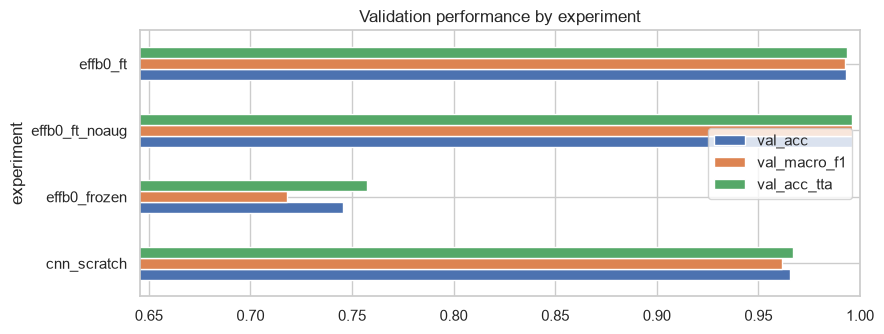

In [49]:
crit = nn.CrossEntropyLoss()
rows, val_probs = [], {}
for name, m in models.items():
    loss, acc, probs, labels = L.evaluate(m, val_loader, crit, device, tta=False)
    loss_t, acc_t, probs_t, _ = L.evaluate(m, val_loader, crit, device, tta=True)
    val_probs[name] = (probs_t, labels)
    rows.append(dict(experiment=name, arch=summaries[name]["arch"],
                     params_M=summaries[name]["params_M"], epochs_run=summaries[name]["epochs_run"],
                     train_min=summaries[name]["train_minutes"],
                     val_loss=loss, val_acc=acc,
                     val_macro_f1=f1_score(labels, probs.argmax(1), average="macro"),
                     val_acc_tta=acc_t,
                     val_macro_f1_tta=f1_score(labels, probs_t.argmax(1), average="macro")))
results = pd.DataFrame(rows).set_index("experiment")
results.to_csv(OUT_DIR / "experiment_results.csv")
display(results.style.format("{:.4f}", subset=["val_loss", "val_acc", "val_macro_f1", "val_acc_tta", "val_macro_f1_tta"])
        .highlight_max(subset=["val_acc", "val_macro_f1", "val_acc_tta"], color="#c6efce")
        .highlight_min(subset=["val_loss"], color="#c6efce"))

fig, ax = plt.subplots(figsize=(9, 3.5))
results[["val_acc", "val_macro_f1", "val_acc_tta"]].plot.barh(ax=ax)
ax.set_xlim(max(0, results.val_acc.min() - 0.1), 1.0); ax.set_title("Validation performance by experiment")
plt.tight_layout(); savefig("11_experiment_comparison"); plt.show()

In [50]:
# Select the final model: best validation macro-F1 with TTA (ties -> lower val loss)
FINAL = results.sort_values(["val_macro_f1_tta", "val_loss"], ascending=[False, True]).index[0]
USE_TTA = results.loc[FINAL, "val_acc_tta"] >= results.loc[FINAL, "val_acc"]
final_model = models[FINAL]
print(f"Final model: {FINAL}  |  test-time augmentation (h-flip): {USE_TTA}")

Final model: effb0_ft_noaug  |  test-time augmentation (h-flip): True


### 5.2 Detailed validation metrics of the final model

In [51]:
v_loss, v_acc, v_probs, v_labels = L.evaluate(final_model, val_loader, crit, device, tta=USE_TTA)
v_pred = v_probs.argmax(1)
print(f"Validation loss     : {v_loss:.4f}")
print(f"Validation accuracy : {v_acc:.4f}")
print(f"Macro F1            : {f1_score(v_labels, v_pred, average='macro'):.4f}")
print(f"Weighted F1         : {f1_score(v_labels, v_pred, average='weighted'):.4f}\n")
report = classification_report(v_labels, v_pred, labels=range(len(CLASS_NAMES)),
                               target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUT_DIR / "classification_report.csv")
display(report_df.style.format("{:.4f}", subset=["precision", "recall", "f1-score"]).format("{:.0f}", subset=["support"]))

Validation loss     : 0.0144
Validation accuracy : 0.9960
Macro F1            : 0.9961
Weighted F1         : 0.9960



,precision,recall,f1-score,support
CatEye,0.9957,0.9960,0.9959,2776
DogEye,0.9940,0.9961,0.9950,2316
CatFace,1.0000,0.9993,0.9996,1388
DogFace,0.9991,1.0000,0.9996,1157
CatMouth,0.9950,0.9957,0.9953,1388
DogMouth,0.9948,0.9974,0.9961,1158
CatNose,0.9957,0.9914,0.9935,1388
DogNose,0.9957,0.9922,0.9939,1158
accuracy,0.9960,0.9960,0.9960,1
macro avg,0.9962,0.9960,0.9961,12729


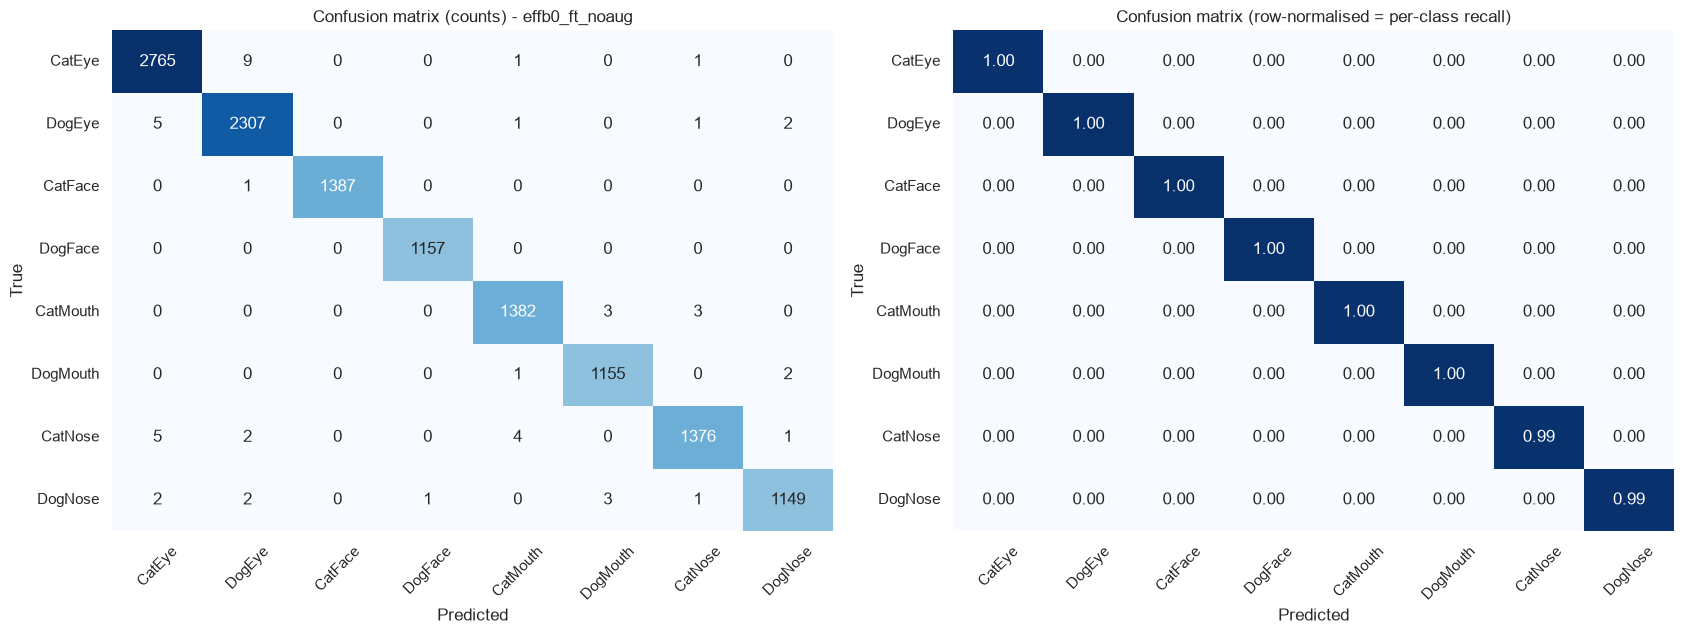

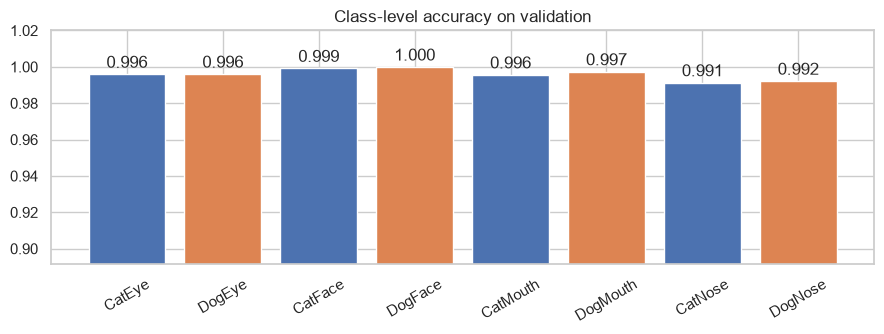

In [52]:
cm = confusion_matrix(v_labels, v_pred, labels=range(len(CLASS_NAMES)))
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
axes[0].set_title(f"Confusion matrix (counts) - {FINAL}")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], vmin=0, vmax=1, cbar=False)
axes[1].set_title("Confusion matrix (row-normalised = per-class recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); savefig("12_confusion_matrix"); plt.show()

per_class_acc = pd.Series(cm.diagonal() / cm.sum(1).clip(min=1), index=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(CLASS_NAMES, per_class_acc.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=2); ax.set_ylim(max(0, per_class_acc.min() - 0.1), 1.02)
ax.set_title("Class-level accuracy on validation"); plt.xticks(rotation=30)
plt.tight_layout(); savefig("13_per_class_accuracy"); plt.show()

### 5.3 Predictions for the Kaggle test set and submission file
The submission is built to match `sample_submission` exactly: same columns, same row order / ids, labels written as class names (or integers if the sample file uses integers).

In [53]:
assert test_df is not None, "No test images found"
test_keys, test_probs = L.predict(final_model, test_loader, device, tta=USE_TTA)
test_pred = test_probs.argmax(1)
np.save(OUT_DIR / "test_probs.npy", test_probs)              # kept for possible ensembling later
pred_by_key = dict(zip(test_keys, test_pred))                  # key = normalised id, e.g. '00017.jpg' -> '17'

if sample_sub is not None:
    # Same columns, same ids (exact spelling) and same row order as the sample submission
    id_col, label_col = sample_sub.columns[0], sample_sub.columns[1]
    submission = sample_sub[[id_col]].copy()
    preds = submission[id_col].map(lambda x: pred_by_key.get(L.norm_id(x)))
    missing = int(preds.isna().sum())
    assert missing == 0, f"{missing} ids in the sample submission have no matching test image"
    preds = preds.astype(int)
    numeric = sample_sub[label_col].astype(str).str.isdigit().all()
    submission[label_col] = preds if numeric else preds.map(idx_to_class)
    assert len(submission) == len(sample_sub) and submission[id_col].equals(sample_sub[id_col])
    assert submission[label_col].isin(CLASS_NAMES if not numeric else range(len(CLASS_NAMES))).all()
else:
    submission = pd.DataFrame({"id": test_keys, "label": [idx_to_class[i] for i in test_pred]})

SUB_PATH = OUT_DIR / "submission.csv"
submission.to_csv(SUB_PATH, index=False)
print(f"Saved {SUB_PATH} with {len(submission)} rows")
display(submission.head())

# Sanity checks + predicted class distribution vs training distribution
pd.DataFrame({
    "test predicted %": (100 * pd.Series(test_pred).map(idx_to_class).value_counts(normalize=True)).reindex(CLASS_NAMES).round(2),
    "train %": (100 * counts / counts.sum()).round(2),
})

Saved outputs\submission.csv with 29443 rows


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


,test predicted %,train %
CatEye,21.43,21.81
DogEye,18.81,18.19
CatFace,10.59,10.90
DogFace,9.54,9.10
CatMouth,10.92,10.90
DogMouth,9.67,9.10
CatNose,9.97,10.90
DogNose,9.08,9.10


### 5.4 Submitting to Kaggle
**Option A – website:** competition page → *Submit Prediction* → upload `outputs/submission.csv` → add a description (e.g. the experiment name) → submit. Take a screenshot of the *My Submissions* page / leaderboard as evidence for the report.

**Option B – Kaggle CLI** (needs `pip install kaggle` and your API token in `C:\Users\<you>\.kaggle\kaggle.json`):
```
kaggle competitions submit -c enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch -f outputs/submission.csv -m "effb0_ft + hflip TTA"
kaggle competitions submissions -c enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch
```
Then enter the public score in the next cell.

In [54]:
KAGGLE_PUBLIC_SCORE = None     # <-- type your leaderboard score here after submitting, e.g. 0.9612

val_metric = accuracy_score(v_labels, v_pred)
print(f"Validation accuracy : {val_metric:.4f}")
print(f"Validation macro-F1 : {f1_score(v_labels, v_pred, average='macro'):.4f}")
if KAGGLE_PUBLIC_SCORE is not None:
    diff = KAGGLE_PUBLIC_SCORE - val_metric
    print(f"Kaggle public score : {KAGGLE_PUBLIC_SCORE:.4f}  (difference vs validation accuracy: {diff:+.4f})")
    if abs(diff) <= 0.01:
        print("-> Validation is a reliable estimate of leaderboard performance (difference within 1 pt).")
    elif diff < 0:
        print("-> Leaderboard is lower: possible distribution shift between train and test, an optimistic "
              "validation split, or randomness of the small public test subset.")
    else:
        print("-> Leaderboard is higher: the public subset may be easier, or validation is pessimistic.")

Validation accuracy : 0.9960
Validation macro-F1 : 0.9961


## 6. Results analysis and improvement strategies

### 6.1 Most common misclassifications

In [55]:
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(len(CLASS_NAMES))
         for j in range(len(CLASS_NAMES)) if i != j and cm[i, j] > 0]
confusions = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
confusions["% of true class"] = (100 * confusions["count"] / confusions.true.map(dict(zip(CLASS_NAMES, cm.sum(1))))).round(2)
print(f"Total validation errors: {int((v_pred != v_labels).sum())} of {len(v_labels)}")
display(confusions.head(10).reset_index(drop=True))

# Are errors about the SPECIES (cat vs dog) or the facial PART (eye/face/mouth/nose)?
species = lambda i: CLASS_NAMES[i][:3]
part = lambda i: CLASS_NAMES[i][3:]
err = v_pred != v_labels
sp_wrong = np.array([species(a) != species(b) for a, b in zip(v_labels, v_pred)])
pt_wrong = np.array([part(a) != part(b) for a, b in zip(v_labels, v_pred)])
error_types = pd.Series({
    "species wrong only (e.g. CatNose->DogNose)": int((sp_wrong & ~pt_wrong).sum()),
    "part wrong only (e.g. DogNose->DogMouth)": int((~sp_wrong & pt_wrong).sum()),
    "both wrong": int((sp_wrong & pt_wrong).sum()),
}, name="errors")
display(error_types.to_frame())
print(f"Species accuracy (cat vs dog): {1 - sp_wrong.mean():.4f}")
print(f"Part accuracy (eye/face/mouth/nose): {1 - pt_wrong.mean():.4f}")

Total validation errors: 51 of 12729


,true,predicted,count,% of true class
0,CatEye,DogEye,9,0.32
1,DogEye,CatEye,5,0.22
2,CatNose,CatEye,5,0.36
3,CatNose,CatMouth,4,0.29
4,CatMouth,CatNose,3,0.22
5,DogNose,DogMouth,3,0.26
6,CatMouth,DogMouth,3,0.22
7,DogMouth,DogNose,2,0.17
8,CatNose,DogEye,2,0.14
9,DogNose,DogEye,2,0.17


,errors
species wrong only (e.g. CatNose->DogNose),20
part wrong only (e.g. DogNose->DogMouth),24
both wrong,7


Species accuracy (cat vs dog): 0.9979
Part accuracy (eye/face/mouth/nose): 0.9976


### 6.2 Misclassified examples

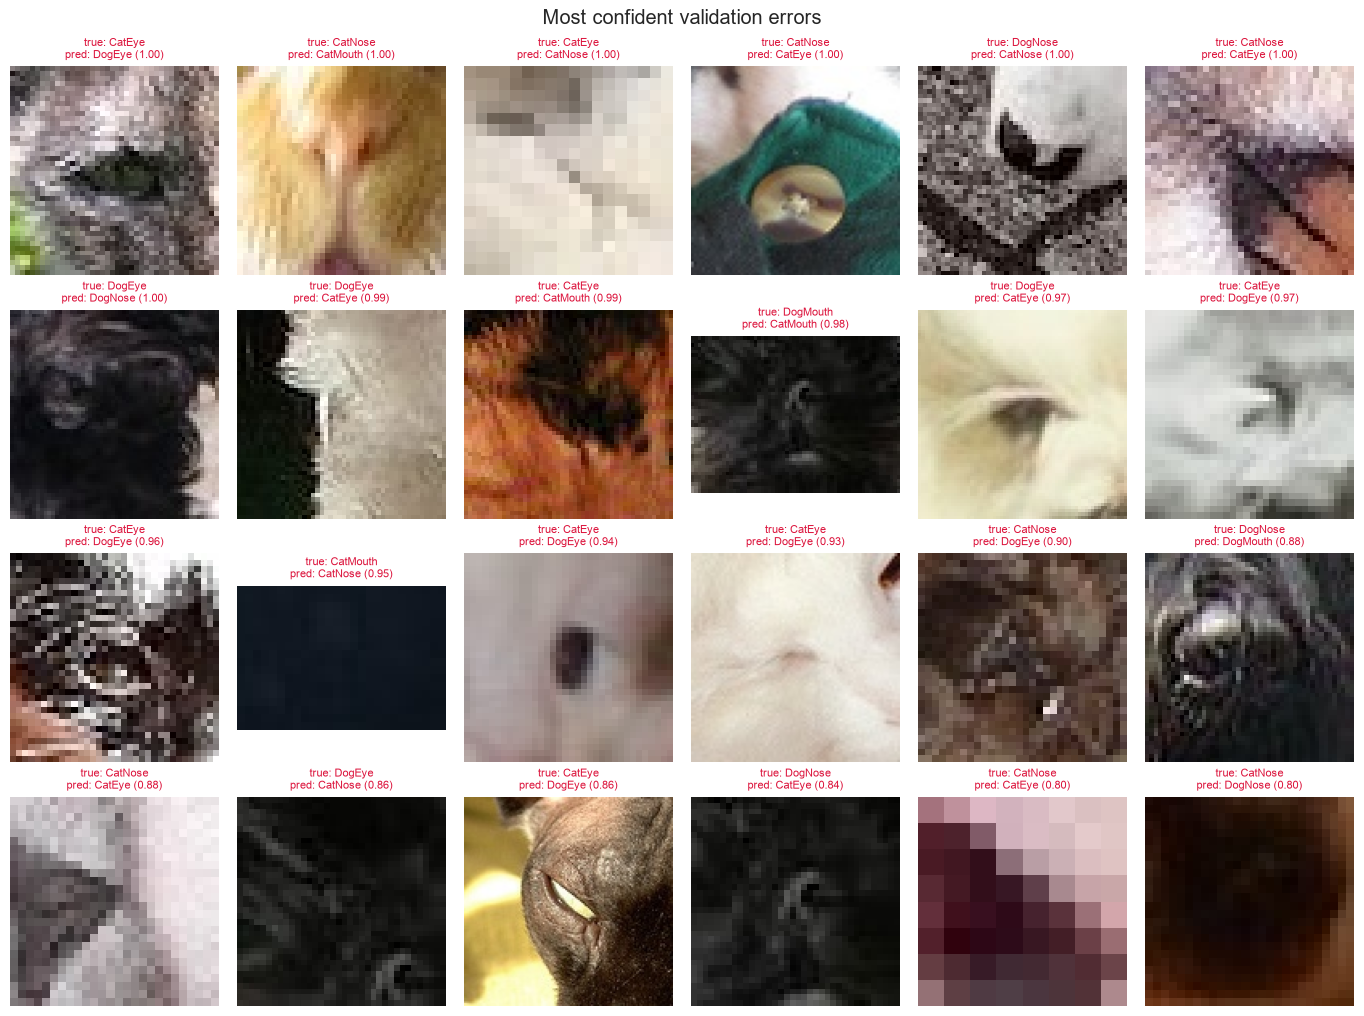

In [56]:
val_res = val_split.copy()
val_res["pred"] = [idx_to_class[i] for i in v_pred]
val_res["conf"] = v_probs.max(1)
val_res["p_true"] = v_probs[np.arange(len(v_labels)), v_labels]
wrong = val_res[val_res.label != val_res.pred].sort_values("conf", ascending=False)
wrong.to_csv(OUT_DIR / "val_misclassified.csv", index=False)

show = wrong.head(24)
if len(show):
    ncol = 6
    nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.3, nrow * 2.6), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, show.iterrows()):
        with Image.open(r.filepath) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"true: {r.label}\npred: {r.pred} ({r.conf:.2f})", fontsize=8, color="crimson")
    plt.suptitle("Most confident validation errors"); plt.tight_layout(); savefig("14_misclassified"); plt.show()
else:
    print("No validation errors!")

### 6.3 Where does the model look? (Grad-CAM)
Heat-maps show which pixels drove the prediction. Errors where the model focuses on background, fur texture or a neighbouring facial part explain many confusions.

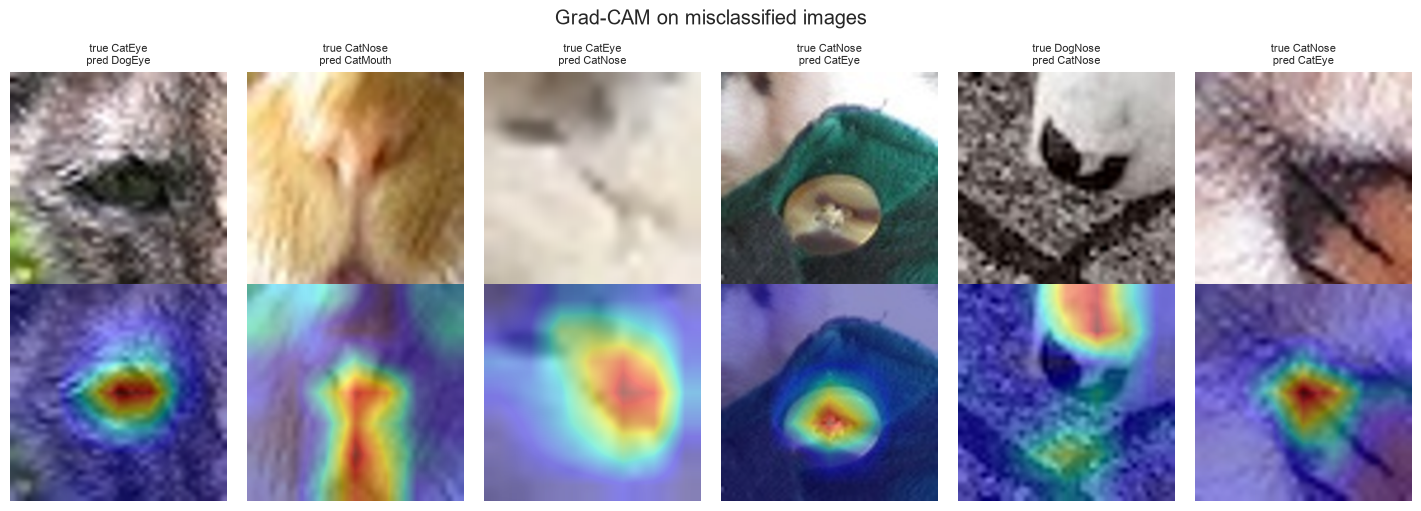

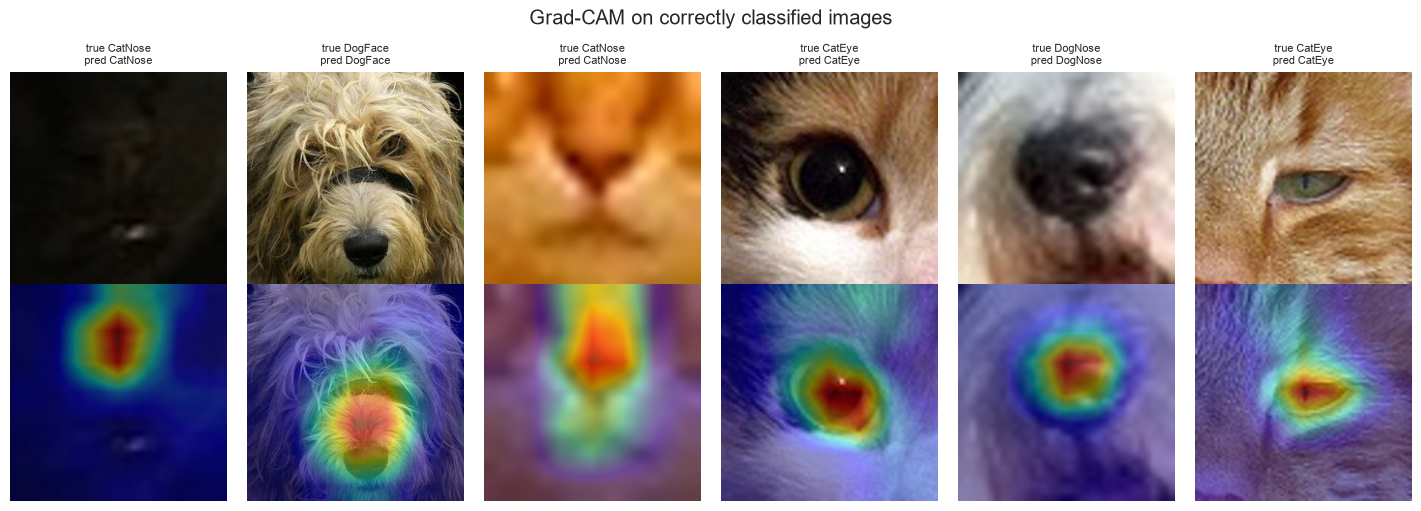

In [57]:
def show_gradcam(df, title, fname, n=6):
    if not hasattr(final_model, "forward_features") or len(df) == 0:
        print("Grad-CAM skipped (model is not a timm CNN or no samples)"); return
    df = df.head(n)
    fig, axes = plt.subplots(2, len(df), figsize=(2.4 * len(df), 5.2), squeeze=False)
    for c, (_, r) in enumerate(df.iterrows()):
        with Image.open(r.filepath) as im:
            x = eval_tf(im.convert("RGB")).unsqueeze(0).to(device)
        cam = L.grad_cam(final_model, x)
        img = L.denormalize(x[0])
        axes[0, c].imshow(img); axes[0, c].set_title(f"true {r.label}\npred {r.pred}", fontsize=8)
        axes[1, c].imshow(img); axes[1, c].imshow(cam, cmap="jet", alpha=0.45)
        axes[0, c].axis("off"); axes[1, c].axis("off")
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

show_gradcam(wrong, "Grad-CAM on misclassified images", "15_gradcam_errors")
show_gradcam(val_res[val_res.label == val_res.pred].sample(min(6, len(val_res)), random_state=SEED),
             "Grad-CAM on correctly classified images", "16_gradcam_correct")

### 6.4 Confidence and data-quality effects

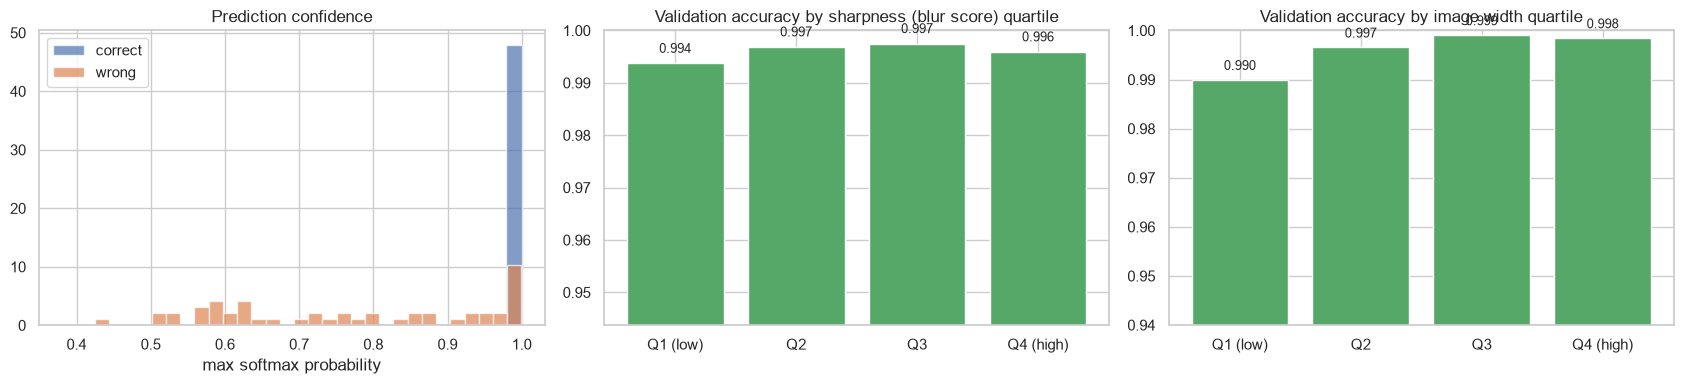

Predictions with confidence < 0.6: 0.2% of validation images; accuracy on them 0.520 vs 0.997 on the rest


In [58]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
correct = val_res.label == val_res.pred
axes[0].hist(val_res.conf[correct], bins=30, alpha=0.7, label="correct", density=True)
if (~correct).any():
    axes[0].hist(val_res.conf[~correct], bins=30, alpha=0.7, label="wrong", density=True)
axes[0].set_title("Prediction confidence"); axes[0].set_xlabel("max softmax probability"); axes[0].legend()

for ax, col, ttl in [(axes[1], "blur", "sharpness (blur score)"), (axes[2], "width", "image width")]:
    q = pd.qcut(val_res[col].rank(method="first"), 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
    acc_q = correct.groupby(q, observed=False).mean()
    ax.bar(acc_q.index.astype(str), acc_q.values, color="#55A868")
    ax.set_ylim(max(0, acc_q.min() - 0.05), 1.0)
    ax.set_title(f"Validation accuracy by {ttl} quartile")
    for i, v in enumerate(acc_q.values):
        ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout(); savefig("17_confidence_quality"); plt.show()

thr = 0.6
low = val_res.conf < thr
print(f"Predictions with confidence < {thr}: {low.mean():.1%} of validation images; "
      f"accuracy on them {correct[low].mean() if low.any() else float('nan'):.3f} vs {correct[~low].mean():.3f} on the rest")

### 6.5 Experiment comparison summary

In [59]:
summary_table = results[["arch", "params_M", "epochs_run", "train_min", "val_loss", "val_acc", "val_macro_f1", "val_acc_tta"]].join(
    diag[["best_epoch", "train_acc_best", "acc_gap_last", "verdict"]])
display(summary_table)

final_summary = {
    "final_experiment": FINAL, "arch": summaries[FINAL]["arch"], "tta": bool(USE_TTA),
    "img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "seed": SEED,
    "val_loss": round(float(v_loss), 4), "val_accuracy": round(float(v_acc), 4),
    "val_macro_f1": round(float(f1_score(v_labels, v_pred, average="macro")), 4),
    "kaggle_public_score": KAGGLE_PUBLIC_SCORE,
    "top_confusions": confusions.head(5).to_dict("records"),
    "data_quality": quality_summary,
}
with open(OUT_DIR / "final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2, default=str)
summary_table.to_csv(OUT_DIR / "summary_table.csv")
print(json.dumps(final_summary, indent=2, default=str))

,arch,params_M,epochs_run,train_min,val_loss,val_acc,val_macro_f1,val_acc_tta,best_epoch,train_acc_best,acc_gap_last,verdict
experiment,,,,,,,,,,,,
cnn_scratch,simple_cnn,1.18,12,30.46,0.197613,0.965590,0.961652,0.966926,11,0.946187,-0.017281,good fit (small gap; early stopping caught the...
effb0_frozen,efficientnet_b0,4.02,6,9.56,0.743273,0.745699,0.717976,0.757561,5,0.718809,-0.016022,underfitting (limited capacity / frozen features)
effb0_ft_noaug,efficientnet_b0,4.02,12,24.60,0.015129,0.995836,0.995854,0.995993,12,0.999843,0.004006,"good fit, may still improve with more epochs"
effb0_ft,efficientnet_b0,4.02,15,31.56,0.109638,0.993322,0.992726,0.993401,11,0.992964,0.002196,good fit (small gap; early stopping caught the...


{
  "final_experiment": "effb0_ft_noaug",
  "arch": "efficientnet_b0",
  "tta": true,
  "img_size": 224,
  "batch_size": 64,
  "seed": 42,
  "val_loss": 0.0144,
  "val_accuracy": 0.996,
  "val_macro_f1": 0.9961,
  "kaggle_public_score": null,
  "top_confusions": [
    {
      "true": "CatEye",
      "predicted": "DogEye",
      "count": 9,
      "% of true class": 0.32
    },
    {
      "true": "DogEye",
      "predicted": "CatEye",
      "count": 5,
      "% of true class": 0.22
    },
    {
      "true": "CatNose",
      "predicted": "CatEye",
      "count": 5,
      "% of true class": 0.36
    },
    {
      "true": "CatNose",
      "predicted": "CatMouth",
      "count": 4,
      "% of true class": 0.29
    },
    {
      "true": "CatMouth",
      "predicted": "CatNose",
      "count": 3,
      "% of true class": 0.22
    }
  ],
  "data_quality": {
    "train_images": 63660,
    "test_images": 29443,
    "corrupted": 0,
    "distinct_sizes": 14347,
    "non_rgb_images": 0,
    "ve

### 6.6 Discussion prompts for the report
Use the numbers produced above (they depend on your run) to write this part in your own words:

**Interpretation of performance** — final validation accuracy / macro-F1 vs Kaggle score (5.4). Is the gap small? What does that say about the validation strategy?

**Difficult classes and common errors** — which pairs dominate the confusion table (6.1)? Are errors mostly *species* errors (cat vs dog at the same part — e.g. noses and mouths look alike at close range) or *part* errors (e.g. a face crop that is zoomed in on the nose)? What do the misclassified images and Grad-CAM maps (6.2–6.3) show: blur, unusual crops, occlusion, possibly wrong labels?

**Reasons for limitations** — image quality (6.4), small / up-sampled images, near-duplicates, label noise, limited data per class, single 80/20 split.

**Effectiveness of choices** — scratch CNN vs transfer learning (E1 vs E4), frozen vs fine-tuned (E2 vs E4), augmentation + label smoothing (E3 vs E4), bigger backbone (E5), TTA (val_acc vs val_acc_tta).

**Realistic improvements** — e.g.
* 5-fold cross-validation and an **ensemble** of the fold models (more reliable validation + usually +0.5–1 pt);
* retrain the final recipe on **train + validation** before submitting;
* larger / newer backbones (ConvNeXt, EfficientNetV2, ViT / Swin) and higher input resolution (288–384 px);
* stronger augmentation (RandAugment / TrivialAugment, MixUp / CutMix) and longer training;
* hyper-parameter search (LR, weight decay, label smoothing) with Optuna;
* more TTA views; checking and cleaning suspected mislabelled images found in 6.2.

**Strengths and weaknesses** — reproducible (fixed seeds, saved splits, config cell, cached stats), leakage-safe split, systematic ablations; weaknesses: single split, limited hyper-parameter search, laptop compute budget.